<a href="https://colab.research.google.com/github/KgadiKatse/Insurance-dataset/blob/main/Health_Insurance_Claims_Data_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Healthcare insurance claims — complete exploratory data analysis

**An annotated, reproducible tutorial for healthcare fraud, waste and abuse (FWA) analytics.**  

**Data:** `synthetic_health_claims.csv` from Kaggle (https://www.kaggle.com/datasets/tejalaveti2306/health-insurance-claims-data-for-fraud-detection?resource=download).

**Scope:** We investigate *data fitness, statistical patterns, possible artefacts, and future feature-engineering hypotheses*. This is **not** a predictive modelling notebook and does **not** determine whether any individual claim is actually fraudulent.

### Questions to be answered

1. What is the observational unit? Are claim, patient, policy and provider identifiers internally consistent?
2. What is the fraud-label base rate, and what does it imply for downstream imbalanced classification?
3. How do claim amounts, frequency, utilization, dates and categorical attributes vary overall and by the synthetic fraud label?
4. Which statistical relationships are strong **in magnitude**, not merely statistically significant?
5. Do the diagnosis/procedure labels, provider IDs, historical counts or geographic fields behave plausibly?
6. Which hypotheses justify feature engineering, and which features should be excluded or independently validated?

**Interpretation rule:** The labels are synthetic; a label association is *not* proof of wrongdoing. Prices, codes and service rules have not been validated against any payer tariff or clinical codebook. Never use this dataset to infer real provider-group fraud rates.

## 0. EDA workflow and reproducibility

The sequence matters: **inspect the raw file → audit integrity → establish an analysis cohort → describe single variables → assess associations → check interactions and entities → synthesize defensible feature hypotheses**. Descriptive association testing is exploratory. Since many hypotheses are examined, we adjust p-values and emphasize effect sizes and replicability.

This notebook automatically creates `figures/` and `tables/` alongside the notebook. Its code does not require Kaggle credentials or internet access because the supplied archive is bundled with the project.

In [6]:
# Import the tools once; keep analysis deterministic and restartable.
from pathlib import Path
import io, zipfile, warnings, platform
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint, proportions_ztest, confint_proportions_2indep
from IPython.display import display
import kagglehub
import os

RANDOM_SEED = 2026
rng = np.random.default_rng(RANDOM_SEED)
ROOT = Path.cwd()
DATA_ARCHIVE = ROOT / 'archive.zip'
FIG = ROOT / 'figures'
TABLE = ROOT / 'tables'
FIG.mkdir(exist_ok=True); TABLE.mkdir(exist_ok=True)
sns.set_theme(style='whitegrid', palette='deep', context='notebook')
plt.rcParams.update({'figure.dpi':110, 'savefig.dpi':160, 'axes.titleweight':'semibold',
                     'figure.constrained_layout.use':True})
print('Python:', platform.python_version(), '| pandas:', pd.__version__, '| numpy:', np.__version__)
print('Input exists:', DATA_ARCHIVE.exists(), '| outputs:', FIG, TABLE)

def saveplot(filename):
    """Save each displayed matplotlib plot as a stand-alone artifact."""
    plt.savefig(FIG / filename, bbox_inches='tight')
    plt.show()

def wilson_table(successes, totals, alpha=.05):
    low, high = proportion_confint(successes, totals, alpha=alpha, method='wilson')
    return low, high

def cramers_v(tab):
    """Descriptive Cramér's V for an r×c contingency table."""
    chi2 = stats.chi2_contingency(tab, correction=False).statistic
    n = tab.to_numpy().sum()
    return np.sqrt(chi2 / (n * min(tab.shape[0]-1, tab.shape[1]-1))) if min(tab.shape)>1 else np.nan

Python: 3.13.16 | pandas: 2.2.3 | numpy: 2.1.3
Input exists: False | outputs: /content/figures /content/tables


## 1. Load **raw** data (do not clean yet)

**Why:** Cleaning immediately hides evidence of duplicate or inconsistent records. We preserve `raw` unchanged, then create a separate analysis copy after making explicit decisions. Numeric-looking codes (for example `Procedure_Code`) are identifiers, not continuous measurements; their ordering and distance have no clinical meaning.

In [7]:
# Download latest version
path = kagglehub.dataset_download("tejalaveti2306/health-insurance-claims-data-for-fraud-detection")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'health-insurance-claims-data-for-fraud-detection' dataset.
Path to dataset files: /kaggle/input/health-insurance-claims-data-for-fraud-detection


In [8]:
# List all files in the downloaded dataset path
files = os.listdir(path)
print("Files in Kaggle download path:", files)

# Identify the CSV file and load it
csv_file = [f for f in files if f.endswith('.csv')][0]
csv_path = os.path.join(path, csv_file)
raw = pd.read_csv(csv_path)

print('\nSuccessfully loaded DataFrame!')
print('Raw shape:', raw.shape)


Files in Kaggle download path: ['synthetic_health_claims.csv']

Successfully loaded DataFrame!
Raw shape: (20100, 30)


In [9]:
print('Raw shape:', raw.shape)
display(raw.head(5))
summary_dtype = pd.DataFrame({'column':raw.columns, 'pandas_type':[str(raw[c].dtype) for c in raw],
    'unique_values':[raw[c].nunique(dropna=False) for c in raw],
    'missing':[raw[c].isna().sum() for c in raw]})
display(summary_dtype)
summary_dtype.to_csv(TABLE/'schema_and_cardinality.csv', index=False)

Raw shape: (20100, 30)


,Patient_ID,Policy_Number,Claim_ID,Claim_Date,Service_Date,Policy_Expiration_Date,Claim_Amount,Patient_Age,Patient_Gender,Patient_City,...,Discharge_Type,Length_of_Stay_Days,Service_Type,Deductible_Amount,CoPay_Amount,Number_of_Previous_Claims_Patient,Number_of_Previous_Claims_Provider,Provider_Patient_Distance_Miles,Claim_Submitted_Late,Is_Fraudulent
0,67349080,XAI956194550,18874,2021-06-16,2021-05-01,2024-11-20,462337.48,28,Female,Houston,...,Rehab/Skilled Nursing,47,Inpatient,3440.06,824.59,0,16,939.08,True,False
1,85973291,XAI215993963,8762,2025-01-19,2025-01-17,2029-04-07,1883481.30,40,Other,Washington,...,Deceased,0,Outpatient,3618.40,851.43,0,6,170.40,False,True
2,62454860,XAI146653263,1920,2023-05-05,2023-03-24,2024-09-04,1500658.89,90,Female,Seattle,...,Deceased,0,Pharmacy,2442.41,616.23,0,2,549.38,True,False
3,58632240,XAI216596381,1316,2021-11-07,2021-11-02,2025-12-24,572237.61,49,Other,Fort Worth,...,Deceased,0,Pharmacy,587.78,459.33,0,2,396.49,False,True
4,96347311,XAI056900359,17039,2024-03-25,2024-02-18,2028-07-30,2088293.84,24,Female,New York,...,Deceased,0,Emergency Room,3047.55,847.40,0,15,865.87,True,False


,column,pandas_type,unique_values,missing
0,Patient_ID,int64,19994,0
1,Policy_Number,object,20000,0
2,Claim_ID,int64,20000,0
3,Claim_Date,object,2019,0
4,Service_Date,object,2093,0
5,Policy_Expiration_Date,object,3479,0
6,Claim_Amount,float64,19999,0
7,Patient_Age,int64,91,0
8,Patient_Gender,object,3,0
9,Patient_City,object,20,0


### Variable roles and the data dictionary

This step makes later feature selection auditable. It is critical to distinguish **administrative keys**, **clinical categorical codes**, **continuous financial measures**, **events/dates**, **utilization counts**, and the **target**. Some variables, such as `Number_of_Previous_Claims_Provider`, sound historical but require verification against known past records before they can be used for prospective risk scoring.

In [10]:
variable_roles = {
    'Patient_ID':'Patient identifier', 'Policy_Number':'Policy identifier', 'Claim_ID':'Claim identifier',
    'Hospital_ID':'Provider/entity identifier', 'Claim_Date':'Submission date', 'Service_Date':'Service date',
    'Policy_Expiration_Date':'Coverage expiration date', 'Claim_Amount':'Financial amount',
    'Patient_Age':'Demographic numeric', 'Patient_Gender':'Demographic category',
    'Patient_City':'Patient geography', 'Patient_State':'Patient geography',
    'Provider_Type':'Provider category', 'Provider_Specialty':'Provider category',
    'Provider_City':'Provider geography', 'Provider_State':'Provider geography',
    'Diagnosis_Code':'Clinical-coded category', 'Procedure_Code':'Clinical-coded category',
    'Number_of_Procedures':'Utilization count', 'Admission_Type':'Episode category',
    'Discharge_Type':'Episode category', 'Length_of_Stay_Days':'Utilization count',
    'Service_Type':'Service category', 'Deductible_Amount':'Financial amount',
    'CoPay_Amount':'Financial amount',
    'Number_of_Previous_Claims_Patient':'Reported history counter',
    'Number_of_Previous_Claims_Provider':'Reported history counter',
    'Provider_Patient_Distance_Miles':'Reported travel distance',
    'Claim_Submitted_Late':'Administrative flag', 'Is_Fraudulent':'Synthetic classification target'
}
assert set(variable_roles)==set(raw.columns)
dictionary = summary_dtype.merge(pd.DataFrame({'column':list(variable_roles), 'role':list(variable_roles.values())}), on='column')
display(dictionary)
dictionary.to_csv(TABLE/'data_dictionary.csv', index=False)

,column,pandas_type,unique_values,missing,role
0,Patient_ID,int64,19994,0,Patient identifier
1,Policy_Number,object,20000,0,Policy identifier
2,Claim_ID,int64,20000,0,Claim identifier
3,Claim_Date,object,2019,0,Submission date
4,Service_Date,object,2093,0,Service date
5,Policy_Expiration_Date,object,3479,0,Coverage expiration date
6,Claim_Amount,float64,19999,0,Financial amount
7,Patient_Age,int64,91,0,Demographic numeric
8,Patient_Gender,object,3,0,Demographic category
9,Patient_City,object,20,0,Patient geography


## 2. Integrity audit: missingness, exact duplicates, duplicate keys and label conflicts

**Research question:** Is one row really one unique claim? Different concepts must not be confused:

- *Exact duplicate row*: every supplied field, including the target, is identical.
- *Repeated Claim_ID*: same administrative claim key appears more than once.
- *Target conflict*: repeated IDs have contradictory `Is_Fraudulent` labels, making a single ground truth impossible without external adjudication.

**Decision for the primary EDA:** Exclude **all** instances of any repeated Claim_ID from label-based calculations. This is conservative and prevents accidental label leakage through duplicate observations. Keep the raw file for an audit trail. In a live system, first investigate whether IDs genuinely represent revisions or adjustments—here the file has no version field.

In [11]:
# We evaluate IDs without changing row order or silently using the first occurrence.
repeated_ids = raw.loc[raw.duplicated('Claim_ID', keep=False), 'Claim_ID'].unique()
label_counts_by_id = raw.groupby('Claim_ID')['Is_Fraudulent'].nunique()
conflicting_ids = label_counts_by_id[label_counts_by_id.gt(1)].index
report = {
    'raw_rows': len(raw), 'raw_columns': raw.shape[1],
    'missing_cells':int(raw.isna().sum().sum()),
    'exact_duplicate_rows_beyond_first':int(raw.duplicated().sum()),
    'claim_ids_repeated':len(repeated_ids),
    'rows_with_repeated_claim_ids':int(raw.Claim_ID.isin(repeated_ids).sum()),
    'repeated_ids_with_conflicting_labels':len(conflicting_ids),
    'rows_removed_for_ambiguous_keys':int(raw.Claim_ID.isin(repeated_ids).sum())
}
display(pd.Series(report, name='result').to_frame())
print('Missing values per field:'); display(raw.isna().sum().to_frame('missing').query('missing > 0'))
assert raw.loc[raw.Claim_ID.isin(repeated_ids)].groupby('Claim_ID').size().eq(2).all()

,result
raw_rows,20100
raw_columns,30
missing_cells,0
exact_duplicate_rows_beyond_first,28
claim_ids_repeated,100
rows_with_repeated_claim_ids,200
repeated_ids_with_conflicting_labels,72
rows_removed_for_ambiguous_keys,200


Missing values per field:


,missing


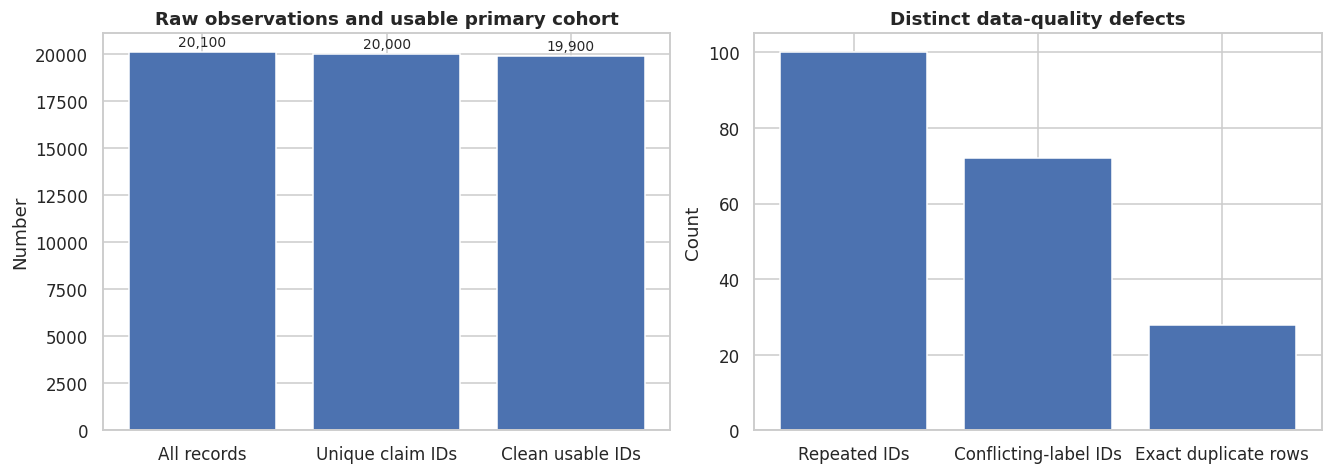

In [12]:
# Visualize key integrity checks; absence of missingness is not evidence of good data quality.
fig, axes = plt.subplots(1,2,figsize=(12,4.2))
axes[0].bar(['All records','Unique claim IDs','Clean usable IDs'],
            [len(raw), raw.Claim_ID.nunique(), (~raw.Claim_ID.isin(repeated_ids)).sum()])
axes[0].set(title='Raw observations and usable primary cohort', ylabel='Number')
for bar in axes[0].patches:
    axes[0].annotate(f'{bar.get_height():,.0f}', (bar.get_x()+bar.get_width()/2,bar.get_height()),
                     ha='center',xytext=(0,4),textcoords='offset points',fontsize=9)
axes[1].bar(['Repeated IDs', 'Conflicting-label IDs','Exact duplicate rows'],
            [len(repeated_ids),len(conflicting_ids),int(raw.duplicated().sum())])
axes[1].set(title='Distinct data-quality defects',ylabel='Count')
saveplot('01_integrity_audit.png')

## 3. Establish the *analysis cohort*, with explicit type handling

- Parse dates (but **do not** arbitrarily impute malformed dates).
- Convert `Procedure_Code` to a string category.
- Encode `Is_Fraudulent` as 0/1 **only for calculation**, retaining its meaning.
- Exclude all 200 rows with repeated `Claim_ID` in the primary analysis.
- Verify keys and date parsing; do **not** normalize monetary values without knowing their currency or units.

In [13]:
df = raw.loc[~raw.Claim_ID.isin(repeated_ids)].copy()
for col in ['Service_Date','Claim_Date','Policy_Expiration_Date']:
    df[col] = pd.to_datetime(df[col], errors='coerce')
df['Procedure_Code'] = df['Procedure_Code'].astype(str)
df['Fraud'] = df['Is_Fraudulent'].astype(int)
assert df.Claim_ID.is_unique
assert not df[['Service_Date','Claim_Date','Policy_Expiration_Date']].isna().any().any()
print('Primary cohort:',df.shape[0],'claims,',df.Hospital_ID.nunique(),'distinct hospital IDs')
print('Dates:',str(df.Claim_Date.min().date()),'through',str(df.Claim_Date.max().date()))

# Sensitivity: quantify how much the key-resolution policy changes prevalence.
sensitivity = pd.DataFrame([
  {'approach':'Uncorrected raw rows','n':len(raw),'label_rate':raw.Is_Fraudulent.mean()},
  {'approach':'Keep first occurrence per Claim_ID (not primary)','n':len(raw.drop_duplicates('Claim_ID')),
   'label_rate':raw.drop_duplicates('Claim_ID').Is_Fraudulent.mean()},
  {'approach':'Exclude all ambiguous Claim_IDs (primary)','n':len(df),'label_rate':df.Fraud.mean()}
])
display(sensitivity); sensitivity.to_csv(TABLE/'duplicate_handling_sensitivity.csv',index=False)

Primary cohort: 19900 claims, 1000 distinct hospital IDs
Dates: 2020-01-01 through 2025-07-11


,approach,n,label_rate
0,Uncorrected raw rows,20100,0.249303
1,Keep first occurrence per Claim_ID (not primary),20000,0.247050
2,Exclude all ambiguous Claim_IDs (primary),19900,0.245377


## 4. Outcome distribution and class imbalance

**Questions:** How frequently is the synthetic label positive? How wide is its binomial confidence interval? Why are accuracy and a 0.5 decision threshold insufficient for evaluating an eventual classifier?

A majority-only classifier would be *accurate* approximately as often as the negative-label share, yet identify **zero** labelled frauds. The fraud prevalence also defines the expected **average precision of a random ranking** in this dataset—not the performance expected on a live insurer population with a different base rate.

Fraud-labelled: 4,883 of 19,900 = 24.54% (95% Wilson CI 23.94%–25.14%)
Non-fraud-labelled: 15,017 (75.46%); majority-class accuracy = 75.46%
Minority:majority ratio = 1 : 3.08


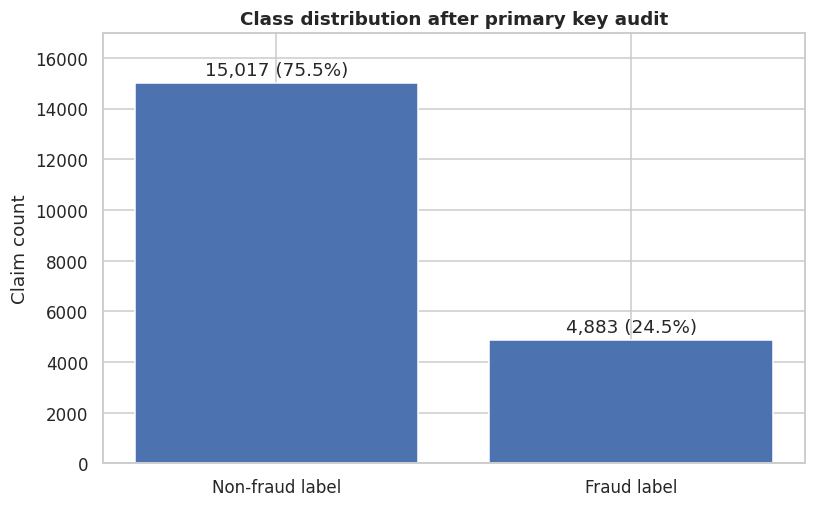

In [14]:
n=len(df); n_pos=int(df.Fraud.sum()); rate=n_pos/n
lo,hi=wilson_table(n_pos,n)
print(f'Fraud-labelled: {n_pos:,} of {n:,} = {rate:.2%} (95% Wilson CI {lo:.2%}–{hi:.2%})')
print(f'Non-fraud-labelled: {n-n_pos:,} ({1-rate:.2%}); majority-class accuracy = {1-rate:.2%}')
print(f'Minority:majority ratio = 1 : {(n-n_pos)/n_pos:.2f}')
fig,ax=plt.subplots(figsize=(7.3,4.5))
values=[n-n_pos,n_pos]; bars=ax.bar(['Non-fraud label','Fraud label'],values)
for b,v in zip(bars,values): ax.annotate(f'{v:,} ({v/n:.1%})', (b.get_x()+b.get_width()/2,v),ha='center',xytext=(0,5),textcoords='offset points')
ax.set(title='Class distribution after primary key audit',ylabel='Claim count',ylim=(0,max(values)*1.13))
saveplot('02_target_prevalence.png')

## 5. Descriptive statistics: scales, quantiles, dispersion and distribution shape

**Why:** Fraud screening variables are usually heteroskedastic, skewed, bounded, zero-inflated or heavy-tailed. Median, IQR, upper quantiles and zero fraction often describe them better than a mean alone. As this is synthetic data, do not assume that a high or extreme value is suspicious without exposure adjustment and policy rules.

We intentionally exclude numeric identifiers (Patient_ID, Claim_ID, Hospital_ID) and numeric procedure codes from continuous statistics.

In [15]:
measures=['Claim_Amount','Patient_Age','Number_of_Procedures','Length_of_Stay_Days',
          'Deductible_Amount','CoPay_Amount','Number_of_Previous_Claims_Patient',
          'Number_of_Previous_Claims_Provider','Provider_Patient_Distance_Miles']
numdesc=df[measures].describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).T
numdesc['skew']=df[measures].skew()
numdesc['zero_fraction']=(df[measures]==0).mean()
display(numdesc.round(3))
numdesc.to_csv(TABLE/'numeric_distribution_summary.csv')

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max,skew,zero_fraction
Claim_Amount,19900.0,1245644.049,698843.079,5516.78,32122.022,148097.309,666786.215,1222531.625,1836808.030,2369052.655,2473857.382,2499688.55,0.051,0.000
Patient_Age,19900.0,45.076,26.295,0.00,0.000,4.000,22.000,45.000,68.000,86.000,90.000,90.00,0.001,0.011
Number_of_Procedures,19900.0,5.508,2.883,1.00,1.000,1.000,3.000,6.000,8.000,10.000,10.000,10.00,-0.000,0.000
Length_of_Stay_Days,19900.0,4.979,13.241,0.00,0.000,0.000,0.000,0.000,0.000,42.000,57.000,60.00,2.717,0.836
Deductible_Amount,19900.0,2507.422,1442.962,0.03,52.859,264.599,1250.392,2505.435,3755.080,4759.196,4953.120,4999.87,-0.004,0.000
CoPay_Amount,19900.0,499.180,288.105,0.02,10.450,50.380,248.585,499.950,748.315,948.230,989.560,999.88,0.001,0.000
Number_of_Previous_Claims_Patient,19900.0,0.000,0.017,0.00,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.00,57.569,1.000
Number_of_Previous_Claims_Provider,19900.0,10.015,6.616,0.00,0.000,0.950,4.000,9.500,15.000,22.000,26.000,34.00,0.402,0.050
Provider_Patient_Distance_Miles,19900.0,499.091,289.943,0.02,10.260,49.320,245.328,497.585,751.105,951.260,989.952,999.98,0.009,0.000


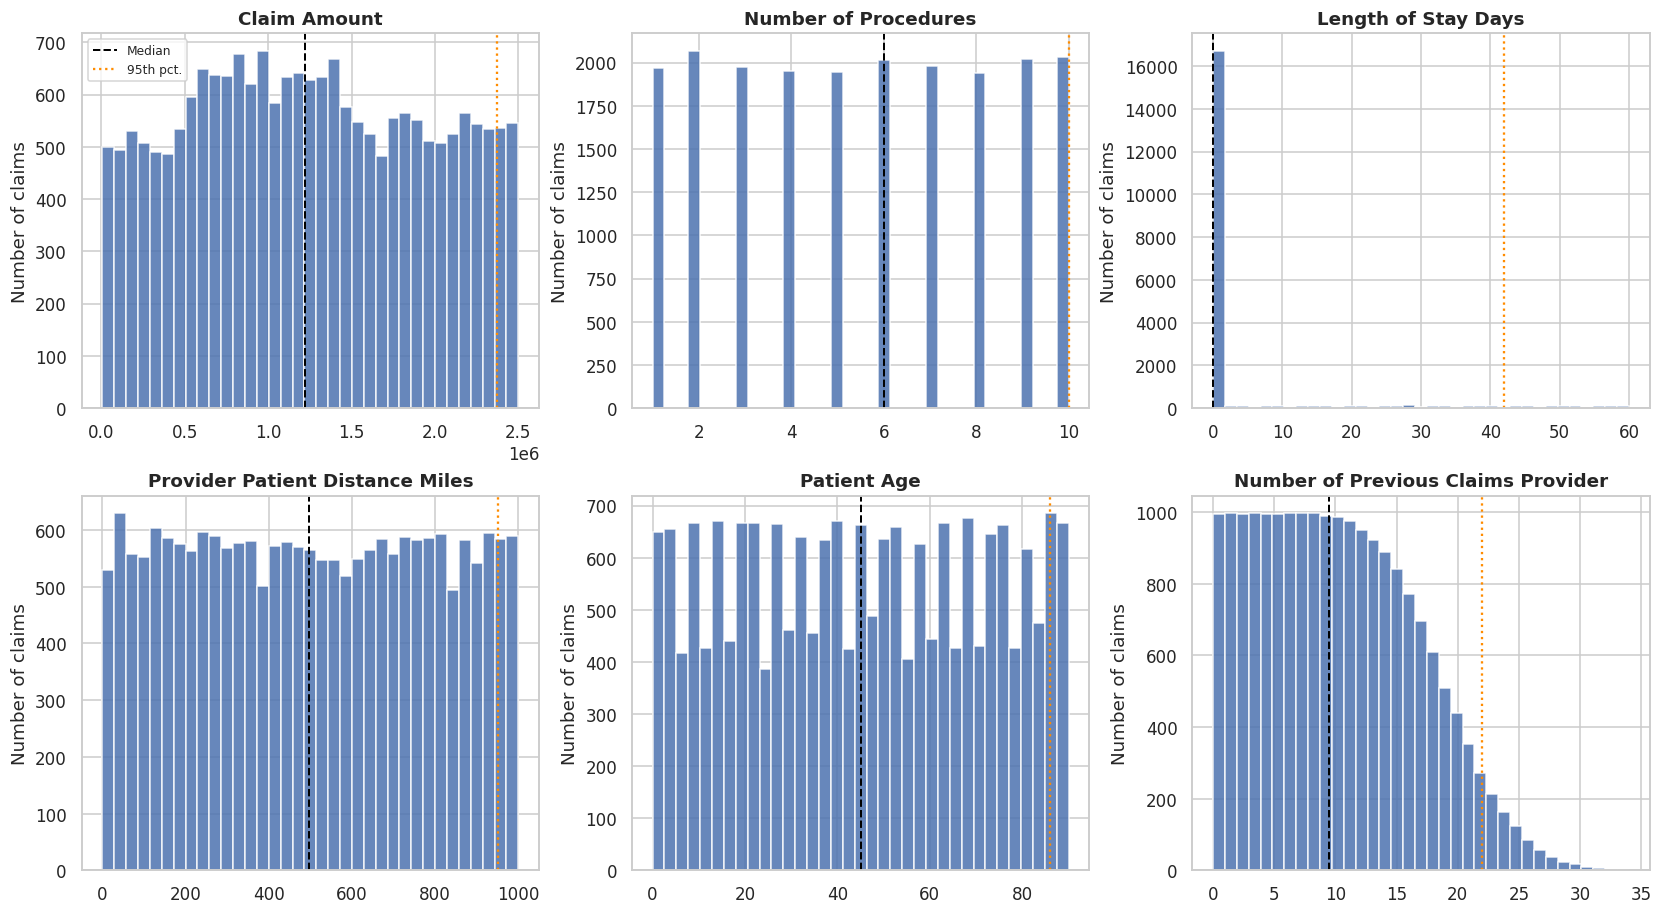

In [16]:
# Use descriptive histograms and upper-percentile markers; each axis uses its natural unit.
columns=['Claim_Amount','Number_of_Procedures','Length_of_Stay_Days',
         'Provider_Patient_Distance_Miles','Patient_Age','Number_of_Previous_Claims_Provider']
fig,axes=plt.subplots(2,3,figsize=(15,8.2))
for ax,c in zip(axes.flat,columns):
    vals=df[c]
    ax.hist(vals,bins=35,alpha=.85)
    ax.axvline(vals.median(),color='black',linestyle='--',linewidth=1.3,label='Median')
    ax.axvline(vals.quantile(.95),color='darkorange',linestyle=':',linewidth=1.5,label='95th pct.')
    ax.set(title=c.replace('_',' '),ylabel='Number of claims')
axes.flat[0].legend(loc='upper left',fontsize=8)
saveplot('03_numeric_distributions.png')

### Financial exposure and extreme values

The amount distribution spans several orders of magnitude. We use logarithmic visualization **for inspection**, not as a claim that a log-normal model is valid. Compute non-parametric Tukey fences and quantiles; describe what falls outside the fence rather than automatically deleting it. The dataset does not specify currency or whether Claim_Amount represents submitted, allowed or paid cost.

Claim amount: median=1,222,531.62; p99=2,473,857.38
Tukey IQR fences: -1,088,246.51 to 3,591,840.75; outside=0


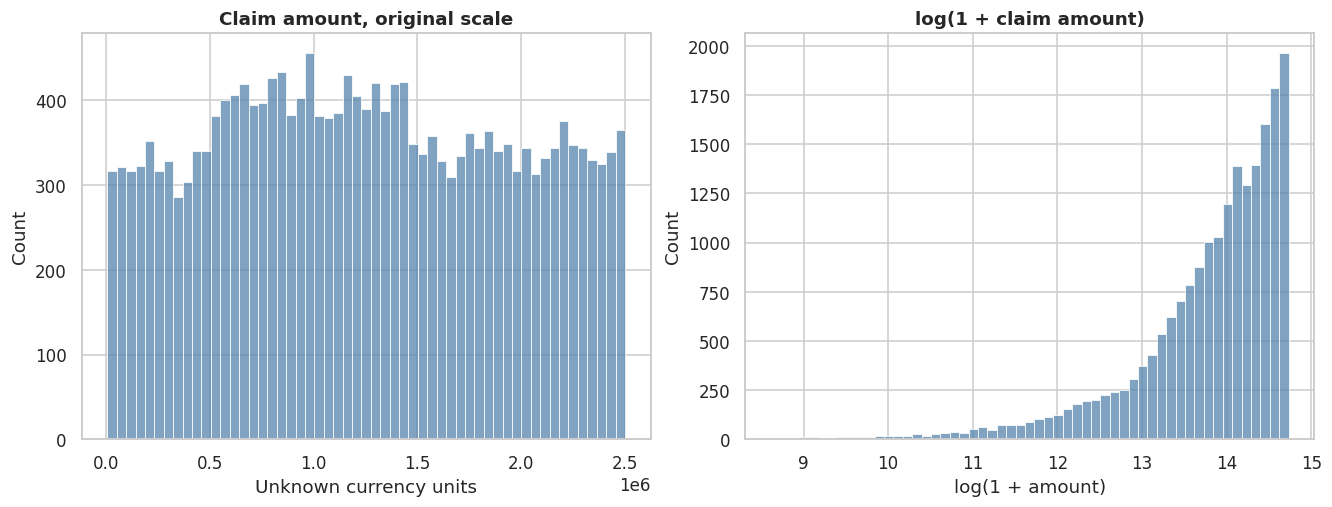

In [17]:
q1,q3=df.Claim_Amount.quantile([.25,.75]); iqr=q3-q1
upper=q3+1.5*iqr; lower=q1-1.5*iqr
print(f'Claim amount: median={df.Claim_Amount.median():,.2f}; p99={df.Claim_Amount.quantile(.99):,.2f}')
print(f'Tukey IQR fences: {lower:,.2f} to {upper:,.2f}; outside={((df.Claim_Amount<lower)|(df.Claim_Amount>upper)).sum():,}')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
sns.histplot(df.Claim_Amount,bins=55,ax=axes[0],color="#5485AC"); axes[0].set(title='Claim amount, original scale',xlabel='Unknown currency units')
sns.histplot(np.log1p(df.Claim_Amount),bins=55,ax=axes[1],color="#5485AC");axes[1].set(title='log(1 + claim amount)',xlabel='log(1 + amount)')
saveplot('04_claim_amount_transform_diagnostics.png')

## 6. Numeric associations with the fraud label: magnitude + statistical evidence

**Hypothesis-testing tutorial:** For each numeric field, compare labelled-positive and labelled-negative distributions using the two-sided Mann–Whitney U test (a test of relative ranks). We supplement p-values with a **rank-biserial effect**, positive when the fraud-labelled observations tend to have larger values, and group medians. Mann–Whitney is not a general test of medians when distribution shapes differ.

We apply the Benjamini–Hochberg false-discovery-rate (FDR) correction to the family of numeric tests. Even statistically significant effects can be practically small with nearly 20,000 observations; use effect size and domain meaning before proposing a feature.

,feature,median_fraud,median_nonfraud,mean_fraud,mean_nonfraud,rank_biserial,p_raw,p_fdr
2,Number_of_Procedures,8.00,5.00,6.410400e+00,5.214760e+00,0.23789,0.00000,0.00000
8,Provider_Patient_Distance_Miles,603.68,456.36,5.656588e+02,4.774459e+02,0.17523,0.00000,0.00000
3,Length_of_Stay_Days,0.00,0.00,2.873850e+00,5.663380e+00,-0.09369,0.00000,0.00000
0,Claim_Amount,1231906.23,1216074.47,1.301939e+06,1.227339e+06,0.06346,0.00000,0.00000
7,Number_of_Previous_Claims_Provider,9.00,10.00,9.901290e+00,1.005147e+01,-0.01328,0.16227,0.24366
4,Deductible_Amount,2542.70,2496.71,2.523206e+03,2.502289e+03,0.00832,0.38172,0.48559
1,Patient_Age,44.00,45.00,4.481814e+01,4.515975e+01,-0.00748,0.43164,0.48559
5,CoPay_Amount,505.08,497.49,5.009815e+02,4.985938e+02,0.00478,0.61507,0.61507
6,Number_of_Previous_Claims_Patient,0.00,0.00,0.000000e+00,4.000000e-04,-0.00040,0.16244,0.24366


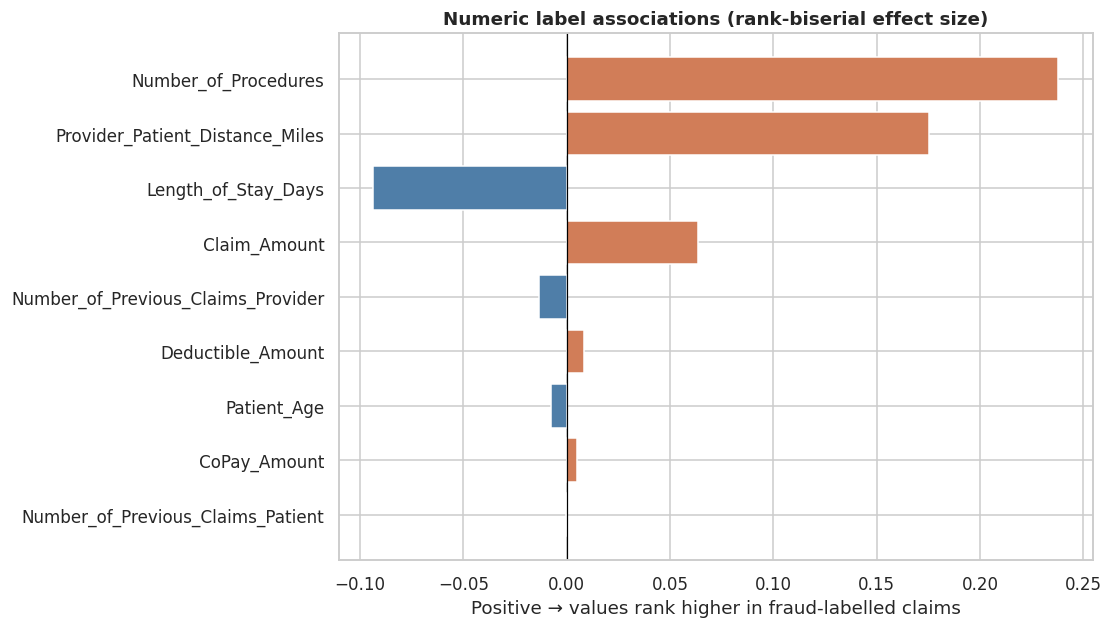

In [18]:
num_tests=[]
for c in measures:
    pos=df.loc[df.Fraud.eq(1),c].to_numpy()
    neg=df.loc[df.Fraud.eq(0),c].to_numpy()
    u,p=stats.mannwhitneyu(pos,neg,alternative='two-sided',method='asymptotic')
    rbc=2*u/(len(pos)*len(neg))-1
    num_tests.append({'feature':c,'median_fraud':np.median(pos),'median_nonfraud':np.median(neg),
                      'mean_fraud':pos.mean(),'mean_nonfraud':neg.mean(),
                      'rank_biserial':rbc,'p_raw':p})
num_tests=pd.DataFrame(num_tests)
num_tests['p_fdr']=multipletests(num_tests.p_raw,method='fdr_bh')[1]
num_tests=num_tests.sort_values('rank_biserial',key=abs,ascending=False)
display(num_tests.round(5));num_tests.to_csv(TABLE/'numeric_statistical_tests.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5.6))
y=np.arange(len(num_tests));v=num_tests.rank_biserial.to_numpy()
ax.barh(y,v,color=np.where(v>=0,'#D17D58','#4F7EA8'))
ax.set_yticks(y,labels=num_tests.feature);ax.invert_yaxis()
ax.axvline(0,color='black',linewidth=.8)
ax.set(title='Numeric label associations (rank-biserial effect size)',xlabel='Positive → values rank higher in fraud-labelled claims')
saveplot('05_numeric_effect_sizes.png')

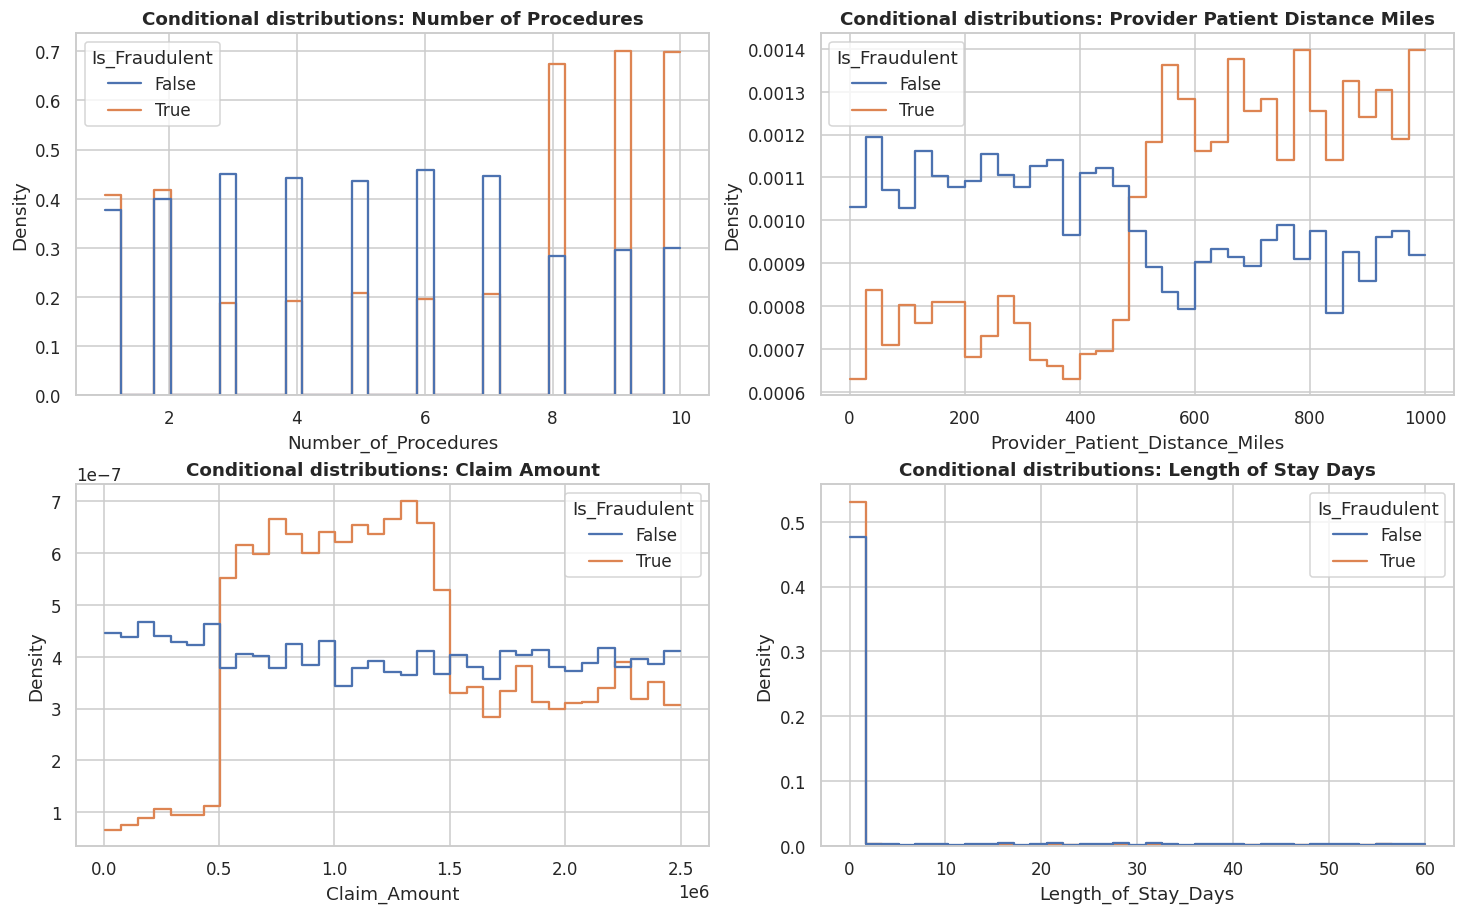

In [19]:
# Distribution overlays make shape differences visible behind the test statistics.
fig,axes=plt.subplots(2,2,figsize=(13.2,8.2))
for ax,c in zip(axes.flat,['Number_of_Procedures','Provider_Patient_Distance_Miles',
                           'Claim_Amount','Length_of_Stay_Days']):
    sns.histplot(data=df,x=c,hue='Is_Fraudulent',hue_order=[False,True],stat='density',
                 common_norm=False,element='step',fill=False,ax=ax,bins=35)
    ax.set_title('Conditional distributions: '+c.replace('_',' '))
saveplot('06_numeric_by_label_overlays.png')

## 7. Categorical associations: contingency tables, chi-square, Cramér's V and FDR

We test whether observed proportions differ across label categories for provider type/specialty, admission, service and diagnosis/procedure codes. **Chi-square** is a test of independence; **Cramér's V** is a normalized effect size, not a causal measure. p-values can become very small in large samples. For sparse contingency tables, expected cell counts should be checked; for high-dimensional code *pairs*, rely more heavily on counts and intervals than on chi-square approximations.

This is a broad exploratory screen. Correcting the full set of p-values reduces, but does not eliminate, the risk of false findings. The synthetic generation mechanism may produce statistically stable yet non-transferable associations.

,feature,levels,chi2,degrees_freedom,p_raw,min_expected_cell,cramers_v,p_fdr
3,Provider_Type,6,2253.06351,5,0.00000,712.57447,0.33648,0.00000
4,Provider_Specialty,10,1832.77611,9,0.00000,427.20116,0.30348,0.00000
9,Admission_Type,5,461.26585,4,0.00000,886.54668,0.15225,0.00000
8,Procedure_Code,20,402.79023,19,0.00000,221.08457,0.14227,0.00000
7,Diagnosis_Code,20,299.86898,19,0.00000,226.72824,0.12276,0.00000
11,Service_Type,6,241.63013,5,0.00000,799.68327,0.11019,0.00000
5,Provider_City,20,41.23457,19,0.00225,230.89965,0.04552,0.00417
2,Patient_State,20,29.96872,19,0.05220,231.14503,0.03881,0.07515
1,Patient_City,20,17.73595,19,0.54014,226.97362,0.02985,0.58515
6,Provider_State,20,11.04299,19,0.92238,228.93663,0.02356,0.92238


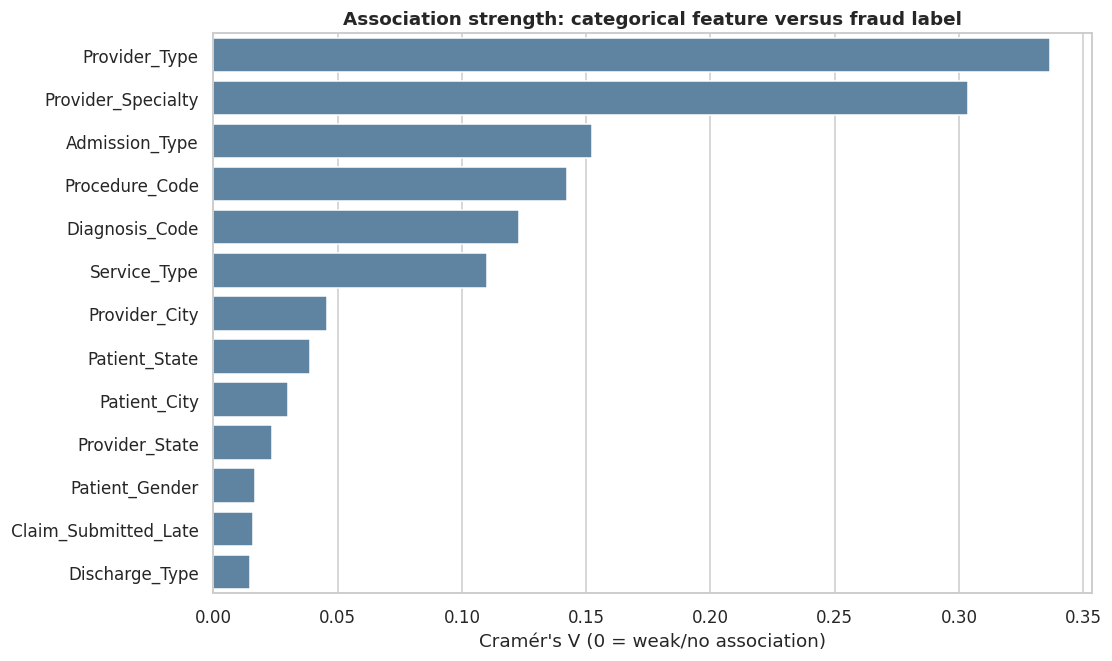

In [20]:
cat_cols=['Patient_Gender','Patient_City','Patient_State','Provider_Type','Provider_Specialty',
          'Provider_City','Provider_State','Diagnosis_Code','Procedure_Code',
          'Admission_Type','Discharge_Type','Service_Type','Claim_Submitted_Late']
cat_tests=[]
for c in cat_cols:
    tab=pd.crosstab(df[c],df.Fraud)
    result=stats.chi2_contingency(tab,correction=False)
    cat_tests.append({'feature':c,'levels':tab.shape[0],'chi2':result.statistic,
      'degrees_freedom':result.dof,'p_raw':result.pvalue,
      'min_expected_cell':result.expected_freq.min(),'cramers_v':cramers_v(tab)})
cat_tests=pd.DataFrame(cat_tests)
cat_tests['p_fdr']=multipletests(cat_tests.p_raw,method='fdr_bh')[1]
cat_tests=cat_tests.sort_values('cramers_v',ascending=False)
display(cat_tests.round(5));cat_tests.to_csv(TABLE/'categorical_statistical_tests.csv',index=False)
fig,ax=plt.subplots(figsize=(10,5.9))
sns.barplot(data=cat_tests,x='cramers_v',y='feature',ax=ax,color='#5485AC')
ax.set(title='Association strength: categorical feature versus fraud label',xlabel="Cramér's V (0 = weak/no association)",ylabel='')
saveplot('07_categorical_association_strength.png')

### Estimate label rates with uncertainty, not ranked rates alone

Provider types, specialties and codes may have different sample sizes. Use **95% Wilson intervals** for each rate. Keep the denominator visible. These intervals summarize sampling uncertainty *conditional on this synthetic sample*, not uncertainty about the data-generation process or future payer populations.

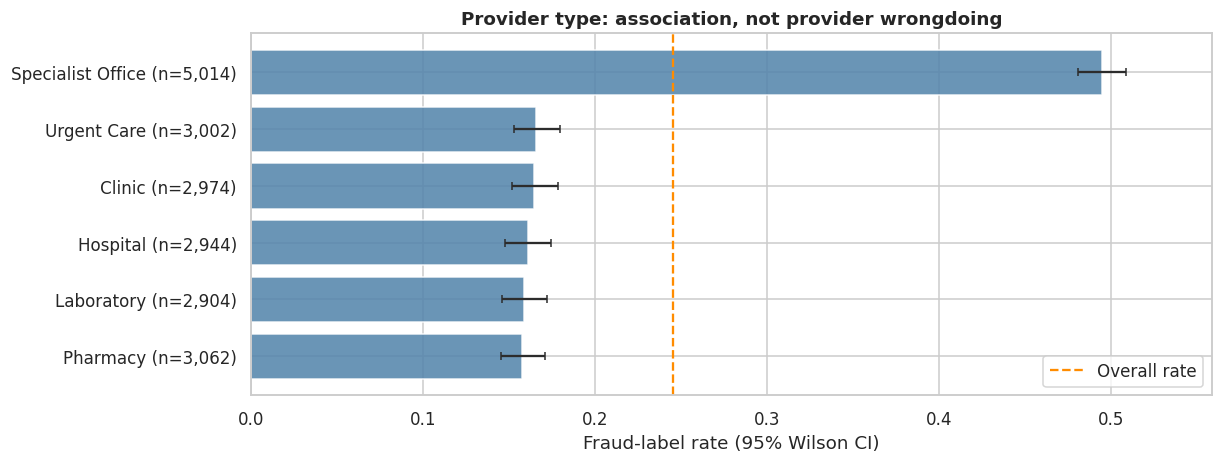

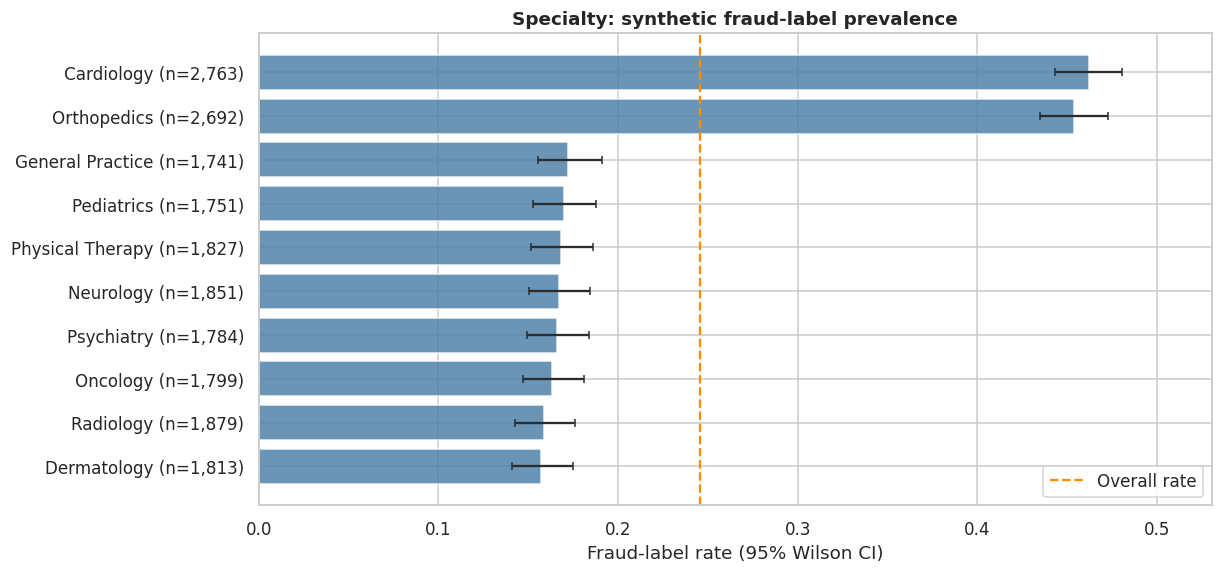

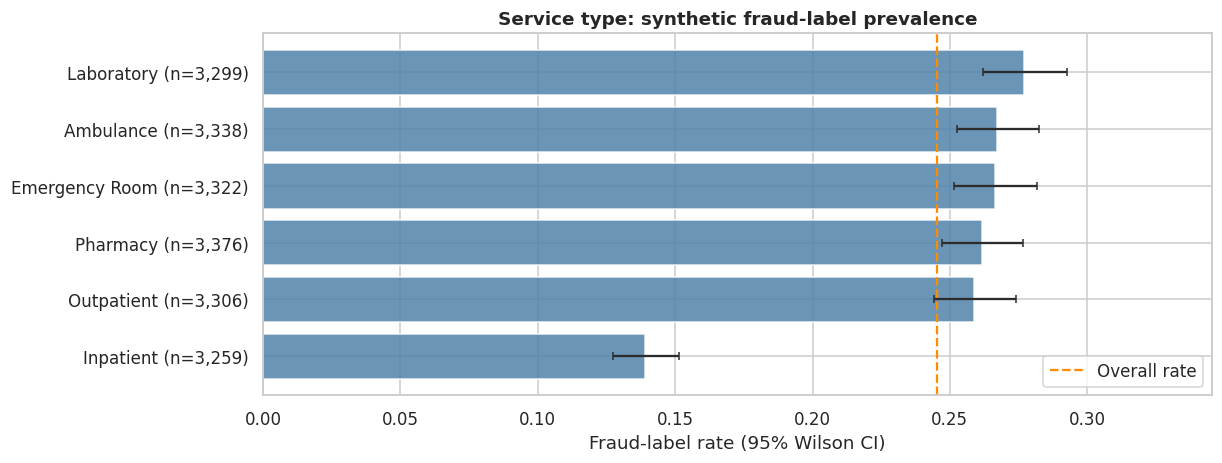

In [21]:
def rate_table(frame, group, min_n=1):
    g=frame.groupby(group,observed=True).Fraud.agg(n='size',fraud_count='sum',label_rate='mean').reset_index()
    g=g[g.n>=min_n].copy()
    g['lower_95'],g['upper_95']=wilson_table(g.fraud_count.to_numpy(),g.n.to_numpy())
    return g.sort_values('label_rate',ascending=False)

def plot_rate(group, filename, title, min_n=1):
    t=rate_table(df,group,min_n=min_n)
    fig,ax=plt.subplots(figsize=(11,max(4.1,len(t)*.38+1.3)))
    y=np.arange(len(t)); v=t.label_rate.to_numpy()
    err=np.vstack([v-t.lower_95.to_numpy(),t.upper_95.to_numpy()-v])
    ax.barh(y,v,color='#5485AC',alpha=.87)
    ax.errorbar(v,y,xerr=err,fmt='none',ecolor='#2C2C2C',capsize=2.5)
    ax.set_yticks(y,[f'{key} (n={int(size):,})' for key,size in zip(t[group],t.n)])
    ax.invert_yaxis();ax.axvline(df.Fraud.mean(),linestyle='--',color='darkorange',label='Overall rate')
    ax.set(xlim=(0,max(t.upper_95.max()+0.05,df.Fraud.mean()+.1)),xlabel='Fraud-label rate (95% Wilson CI)',title=title)
    ax.legend(loc='lower right');saveplot(filename)
    return t

type_rate=plot_rate('Provider_Type','08_provider_type_rates.png','Provider type: association, not provider wrongdoing')
spec_rate=plot_rate('Provider_Specialty','09_specialty_rates.png','Specialty: synthetic fraud-label prevalence')
service_rate=plot_rate('Service_Type','10_service_type_rates.png','Service type: synthetic fraud-label prevalence')
type_rate.to_csv(TABLE/'provider_type_rate_ci.csv',index=False)
spec_rate.to_csv(TABLE/'specialty_rate_ci.csv',index=False)
service_rate.to_csv(TABLE/'service_type_rate_ci.csv',index=False)

### Worked inferential example: Specialist Office versus all other categories

A **two-sample proportion comparison** estimates the difference in label prevalence with its 95% confidence interval. A large rate difference motivates investigation of **how the synthetic target was generated** and possible interactions; it does *not* warrant treating a provider category as evidence of fraud. This is an association, not a randomized or risk-adjusted causal effect.

In [22]:
mask=df.Provider_Type.eq('Specialist Office')
x1=int(df.loc[mask,'Fraud'].sum());n1=int(mask.sum())
x0=int(df.loc[~mask,'Fraud'].sum());n0=int((~mask).sum())
diff=x1/n1-x0/n0
z,p=proportions_ztest([x1,x0],[n1,n0])
ci=confint_proportions_2indep(x1,n1,x0,n0,compare='diff',method='newcomb')
print(f'Specialist Office: {x1}/{n1} = {x1/n1:.2%}; others: {x0}/{n0} = {x0/n0:.2%}')
print(f'Absolute risk difference: {diff:+.2%}; Newcombe 95% CI [{ci[0]:+.2%},{ci[1]:+.2%}]')
print(f'Two-proportion z test: z={z:.2f}; p={p:.3g} (association, not causation)')

Specialist Office: 2481/5014 = 49.48%; others: 2402/14886 = 16.14%
Absolute risk difference: +33.35%; Newcombe 95% CI [+31.84%,+34.85%]
Two-proportion z test: z=47.46; p=0 (association, not causation)


## 8. Confounding and interactions: provider type × specialty

**Why:** If speciality mix differs between provider types, a simple provider-category fraud-label rate can be confounded. Look at the cross-tabulated *rate* and the sample size of every cell. Cells with few claims are visually masked so that noisy percentages are not over-interpreted. This suggests interaction features for later models—but they must be validated out of sample.

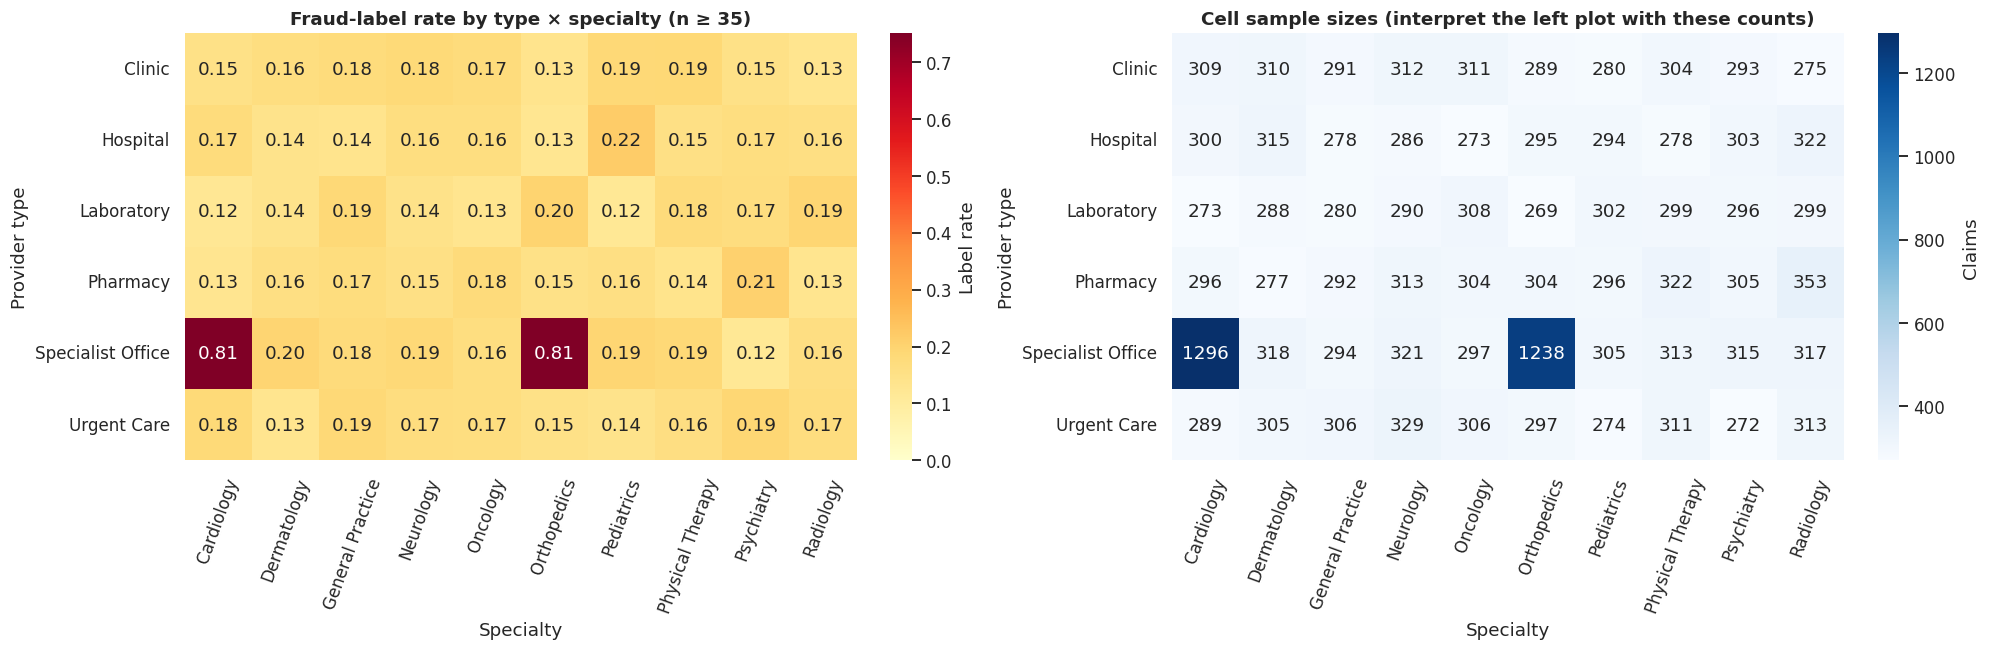

In [23]:
rg=df.pivot_table(index='Provider_Type',columns='Provider_Specialty',values='Fraud',aggfunc='mean',observed=True)
ng=df.pivot_table(index='Provider_Type',columns='Provider_Specialty',values='Fraud',aggfunc='size',observed=True)
fig,axes=plt.subplots(1,2,figsize=(18,5.8))
sns.heatmap(rg,mask=ng.lt(35),cmap='YlOrRd',vmin=0,vmax=.75,annot=True,fmt='.2f',ax=axes[0],cbar_kws={'label':'Label rate'})
axes[0].set(title='Fraud-label rate by type × specialty (n ≥ 35)',xlabel='Specialty',ylabel='Provider type')
sns.heatmap(ng,annot=True,fmt='.0f',cmap='Blues',ax=axes[1],cbar_kws={'label':'Claims'})
axes[1].set(title='Cell sample sizes (interpret the left plot with these counts)',xlabel='Specialty',ylabel='Provider type')
for a in axes: a.tick_params(axis='x',rotation=70)
saveplot('11_provider_type_specialty_interactions.png')

### 8.1 Follow the interaction: a likely synthetic target-generation signature

The previous heatmap reveals a much stronger relationship in a specific **intersection** of features than in either variable alone: cardiology and orthopedics billed under `Specialist Office` show an exceptionally high label rate. Test this hypothesis explicitly by forming four *mutually exclusive* groups and reporting group sizes and binomial uncertainty. Contrast the intersection with each remainder before suggesting it as an interaction candidate.

**Interpretation:** This is a *possible data-generation artefact*, not a clinical or legal conclusion. If the synthetic target was constructed using these categories, predictive models can appear highly accurate by recovering the simulator's heuristic. Moreover, defining such a composite hypothesis after inspecting the plot is **post-hoc exploration**: its p-values should not be treated as confirmatory evidence.

,Type_Specialty_Stratum,n,fraud_count,label_rate,lower_95,upper_95
2,Specialist + Cardio/Ortho,2534,2051,0.809392,0.793635,0.824213
3,Specialist + other specialty,2480,430,0.173387,0.158995,0.188789
1,Non-specialist + other specialty,11965,1956,0.163477,0.156959,0.170211
0,Non-specialist + Cardio/Ortho,2921,446,0.152687,0.140100,0.166187


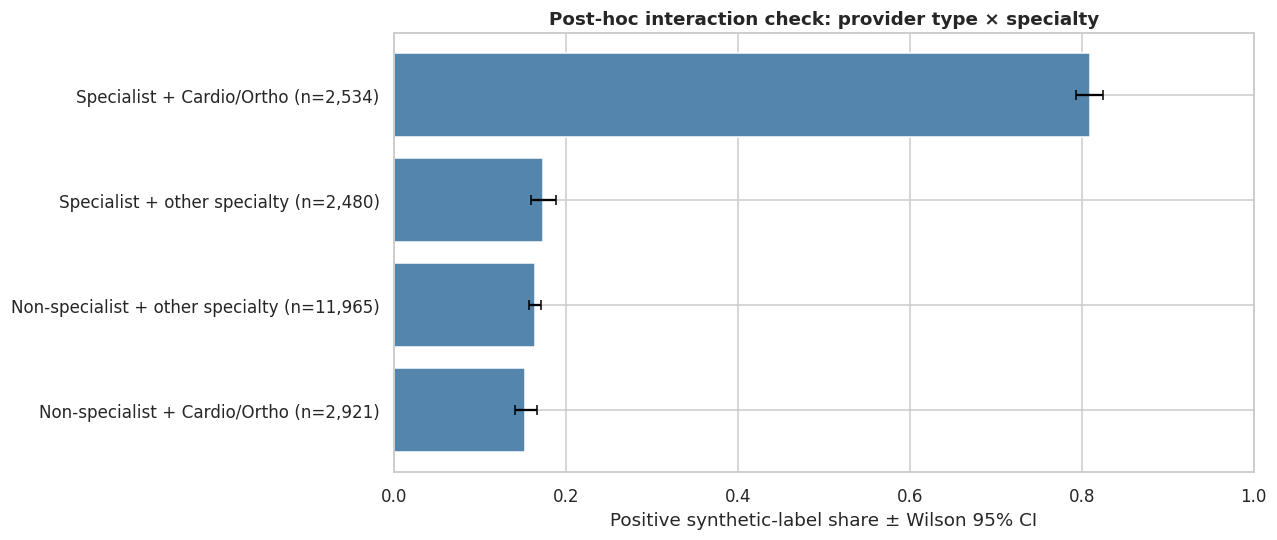

In [24]:
# Define interpretable strata using the previous heatmap (post-hoc EDA hypothesis).
is_specialist=df.Provider_Type.eq('Specialist Office')
is_cardio_ortho=df.Provider_Specialty.isin(['Cardiology','Orthopedics'])
df['Type_Specialty_Stratum']=np.select(
    [is_specialist & is_cardio_ortho,
     is_specialist & ~is_cardio_ortho,
     ~is_specialist & is_cardio_ortho],
    ['Specialist + Cardio/Ortho','Specialist + other specialty',
     'Non-specialist + Cardio/Ortho'], default='Non-specialist + other specialty')
intersection_rates=rate_table(df,'Type_Specialty_Stratum')
display(intersection_rates)
intersection_rates.to_csv(TABLE/'provider_specialty_intersection_rates.csv',index=False)
fig,ax=plt.subplots(figsize=(11.5,4.8))
order=intersection_rates
v=order.label_rate.to_numpy();e=np.vstack([v-order.lower_95,order.upper_95-v])
y=np.arange(len(order))
ax.barh(y,v,color='#5485AC');ax.errorbar(v,y,xerr=e,fmt='none',ecolor='black',capsize=3)
ax.set_yticks(y,[f'{name} (n={cnt:,})' for name,cnt in zip(order.Type_Specialty_Stratum,order.n)])
ax.invert_yaxis();ax.set(xlabel='Positive synthetic-label share ± Wilson 95% CI',
                           title='Post-hoc interaction check: provider type × specialty',xlim=(0,1))
saveplot('11b_specialist_cardiology_orthopedics_interaction.png')

## 9. Demographics: age and gender as contextual variables

Group ages into clinically interpretable bins and show both frequency and label rates. A low/high rate may reflect simulation rules, admission/service mix or selection effects. In real-world deployment, evaluate fairness and legality before using demographic attributes for automated negative decisions.

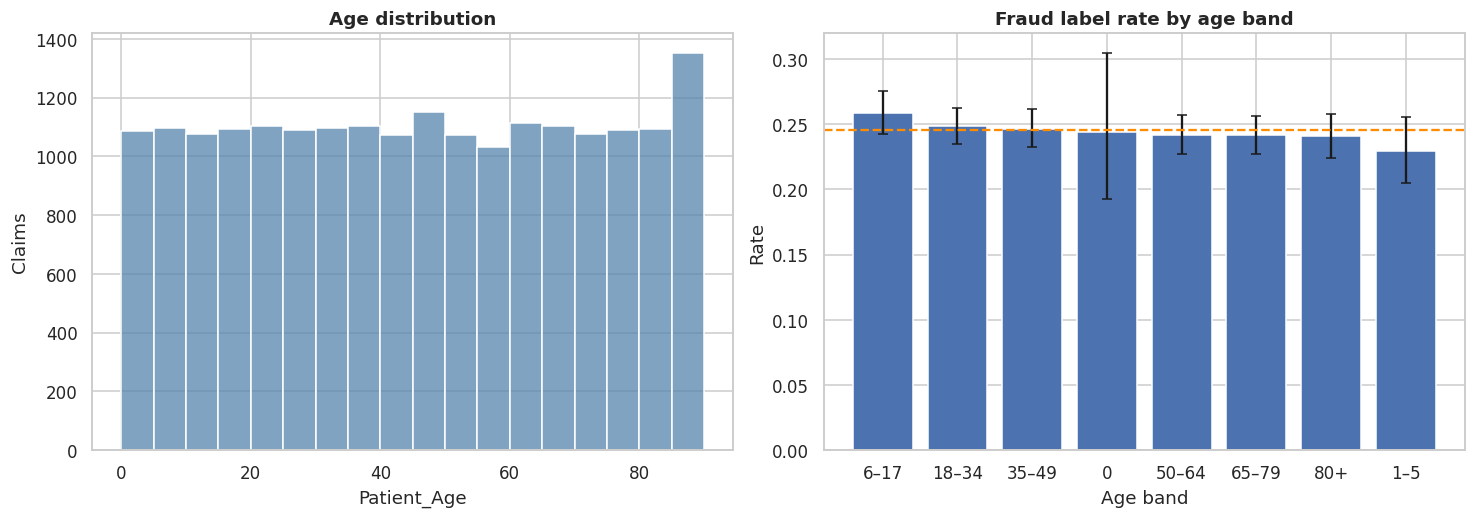

,Age_Band,n,fraud_count,label_rate,lower_95,upper_95
2,6–17,2620,678,0.258779,0.242370,0.275893
3,18–34,3715,924,0.248721,0.235085,0.262877
4,35–49,3330,821,0.246547,0.232205,0.261472
0,0,225,55,0.244444,0.192889,0.304580
5,50–64,3218,779,0.242076,0.227590,0.257177
6,65–79,3268,790,0.241738,0.227368,0.256715
7,80+,2443,588,0.240688,0.224151,0.258038
1,1–5,1081,248,0.229417,0.205337,0.255414


Gender rates:


,Patient_Gender,n,fraud_count,label_rate,lower_95,upper_95
2,Other,6656,1688,0.253606,0.243298,0.264198
0,Female,6639,1637,0.246573,0.236354,0.257086
1,Male,6605,1558,0.235882,0.225799,0.246272


In [25]:
age_bins=[-1,0,5,17,34,49,64,79,120]
age_labels=['0','1–5','6–17','18–34','35–49','50–64','65–79','80+']
df['Age_Band']=pd.cut(df.Patient_Age,bins=age_bins,labels=age_labels)
age_rate=rate_table(df,'Age_Band')
fig,axes=plt.subplots(1,2,figsize=(13.3,4.6))
sns.histplot(data=df,x='Patient_Age',binwidth=5,ax=axes[0],color='#5485AC');axes[0].set(title='Age distribution',ylabel='Claims')
axes[1].bar(age_rate.Age_Band.astype(str),age_rate.label_rate,yerr=[age_rate.label_rate-age_rate.lower_95,age_rate.upper_95-age_rate.label_rate],capsize=3)
axes[1].axhline(df.Fraud.mean(),color='darkorange',linestyle='--');axes[1].set(title='Fraud label rate by age band',ylabel='Rate',xlabel='Age band')
saveplot('12_patient_age_and_labels.png')
display(age_rate)
print('Gender rates:');display(rate_table(df,'Patient_Gender'))

## 10. Time series, reporting delay and seasonality

**Data availability:** `Service_Date` is when treatment occurred; `Claim_Date` is a submission/claim date. For detection at submission, both can be available, while patient-provider *future* history is not. The time series also tells us if a later time period should be held out for model benchmarking.

Monthly rates fluctuate partly due to monthly claim counts. Unfinished boundary years must not be interpreted as structural trend changes. We calculate `Submission_Delay_Days` and independently verify the flag `Claim_Submitted_Late`.

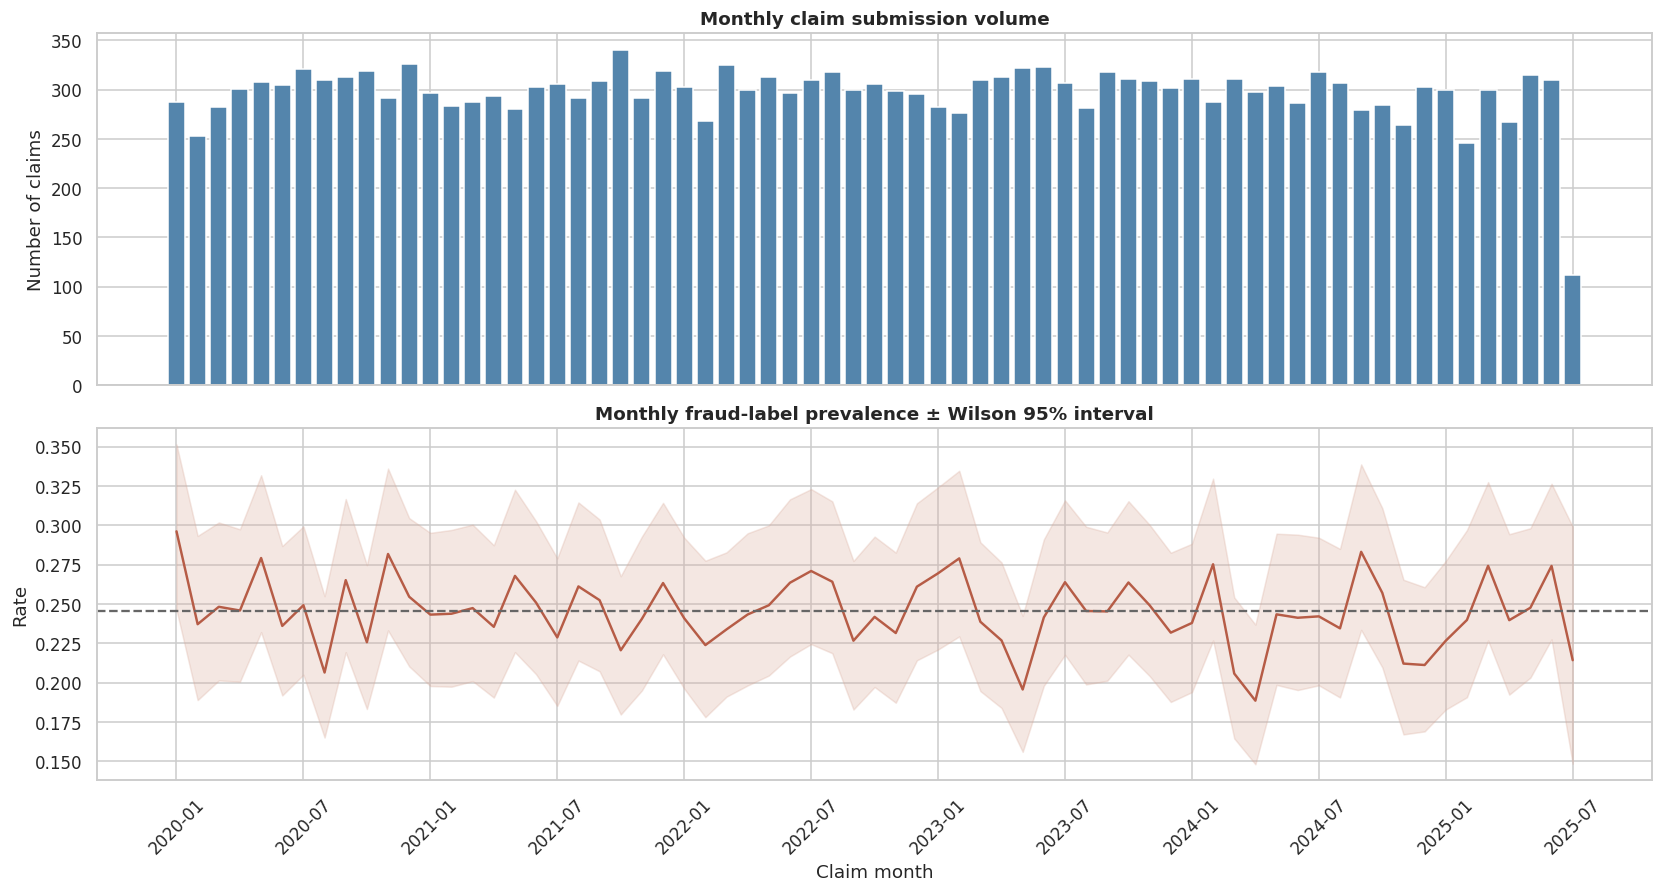

In [26]:
df['Submission_Delay_Days']=(df.Claim_Date-df.Service_Date).dt.days
df['Days_to_Expiration_on_Service']=(df.Policy_Expiration_Date-df.Service_Date).dt.days
df['Month']=df.Claim_Date.dt.to_period('M').astype(str)
df['Year']=df.Claim_Date.dt.year
monthly=df.groupby('Month').Fraud.agg(n='size',fraud_count='sum',rate='mean').reset_index()
monthly['low'],monthly['high']=wilson_table(monthly.fraud_count,monthly.n)
monthly.to_csv(TABLE/'monthly_claim_and_label_rates.csv',index=False)
fig,axes=plt.subplots(2,1,figsize=(15,8.0),sharex=True)
x=np.arange(len(monthly))
axes[0].bar(x,monthly.n,color='#5485AC');axes[0].set(title='Monthly claim submission volume',ylabel='Number of claims')
axes[1].plot(x,monthly.rate,color='#B65C46',linewidth=1.6)
axes[1].fill_between(x,monthly.low.to_numpy(),monthly.high.to_numpy(),color='#D9AA9A',alpha=.28)
axes[1].axhline(df.Fraud.mean(),linestyle='--',color='#666666')
axes[1].set(title='Monthly fraud-label prevalence ± Wilson 95% interval',ylabel='Rate',xlabel='Claim month')
ticks=x[::6];axes[1].set_xticks(ticks,monthly.Month.iloc[ticks],rotation=45)
saveplot('13_monthly_claim_volume_and_fraud_rate.png')

Submission lag min/median/p95/max: 0 45.0 86.0 90
Late flag counts by lag > 30 days:


Claim_Submitted_Late,False,True
Submission_Delay_Days,,
False,6818,0
True,0,13082


Agreement: 1.0


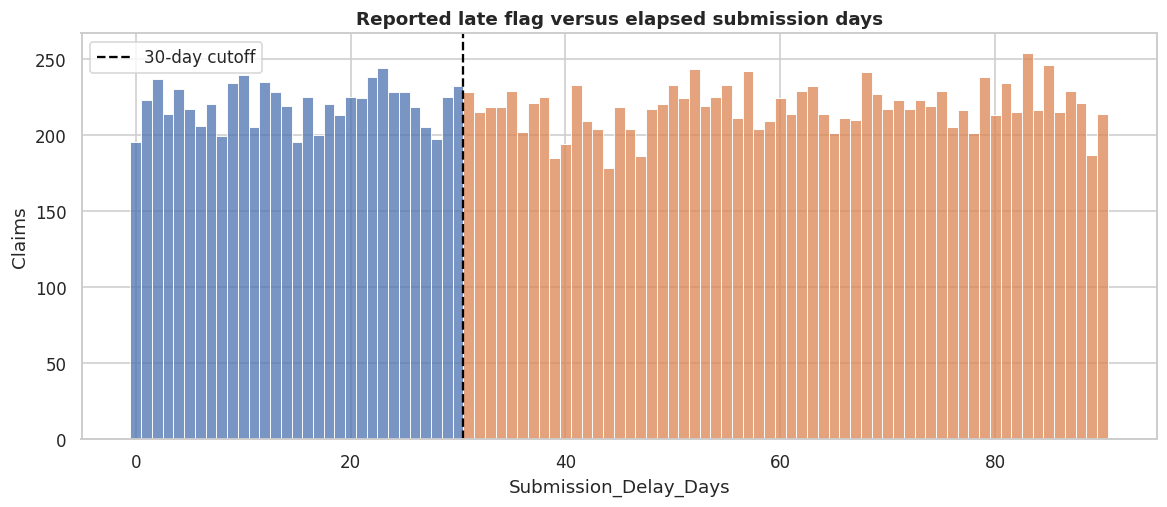

In [27]:
# Data-quality rule check: compare the recorded late indicator with a threshold inferred from dates.
print('Submission lag min/median/p95/max:',df.Submission_Delay_Days.min(),
      df.Submission_Delay_Days.median(),df.Submission_Delay_Days.quantile(.95),df.Submission_Delay_Days.max())
print('Late flag counts by lag > 30 days:')
lag_tab=pd.crosstab(df.Submission_Delay_Days.gt(30),df.Claim_Submitted_Late)
display(lag_tab)
print('Agreement:',(df.Submission_Delay_Days.gt(30)==df.Claim_Submitted_Late).mean())
fig,ax=plt.subplots(figsize=(10.5,4.5))
sns.histplot(data=df,x='Submission_Delay_Days',hue='Claim_Submitted_Late',multiple='stack',discrete=True,ax=ax)
ax.axvline(30.5,color='black',linestyle='--',label='30-day cutoff');ax.legend(['30-day cutoff'])
ax.set(title='Reported late flag versus elapsed submission days',ylabel='Claims')
saveplot('14_submission_delay_and_late_flag.png')

## 11. Temporal, policy and episode rule plausibility

A fraud-analytics pipeline should distinguish **rule-based exceptions** from statistical anomalies. We can test basic chronology (claim before service, service after policy expiry), as well as ambiguous utilization conventions (e.g., inpatient length of stay). However, these are only preliminary data-quality checks: real billing validity requires eligibility-at-date, contractual rules, modifiers, reimbursement policies and case review.

,check,count,percentage
8,Newborn admission with age > 1,3542,0.177990
9,Deceased discharge with zero stay,3278,0.164724
1,Service AFTER policy expiry,0,0.000000
0,Claim submission BEFORE service,0,0.000000
2,Claim submission AFTER policy expiry,0,0.000000
3,Negative claimed amount,0,0.000000
5,Negative stay duration,0,0.000000
4,No procedures billed,0,0.000000
7,Non-inpatient with positive stay,0,0.000000
6,Inpatient with zero stay,0,0.000000


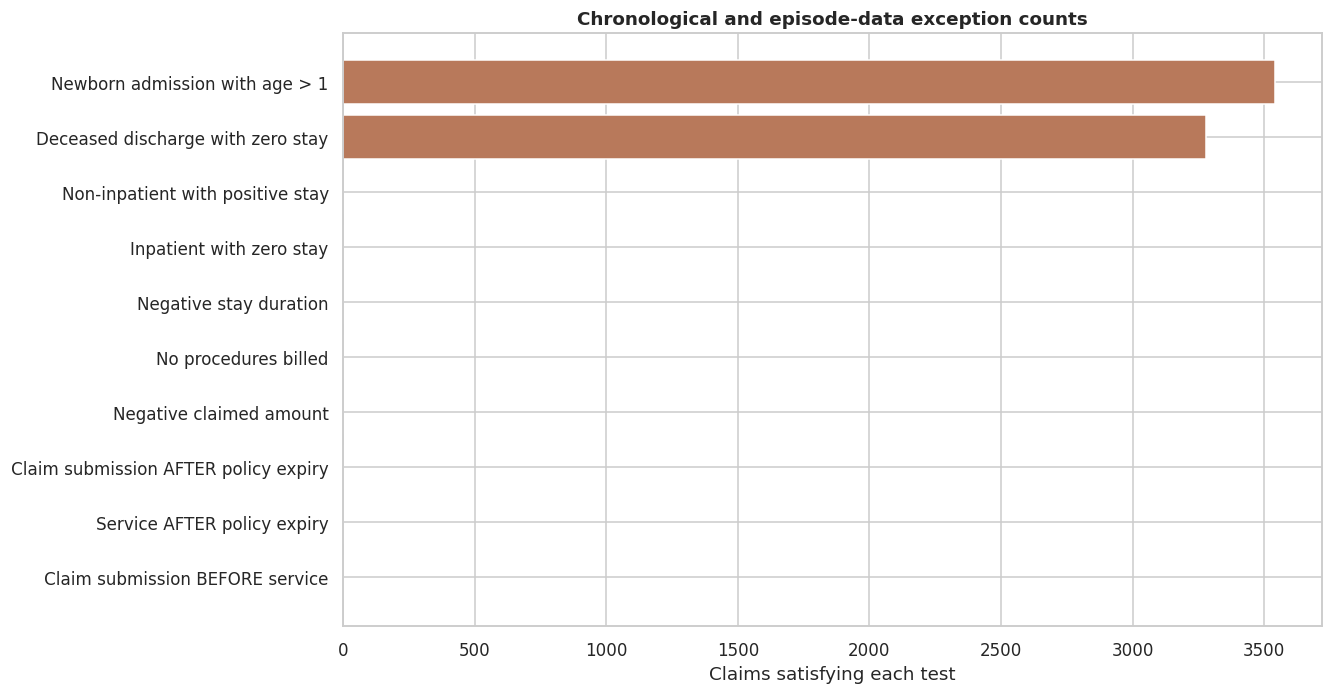

In [28]:
checks={
 'Claim submission BEFORE service':(df.Claim_Date<df.Service_Date),
 'Service AFTER policy expiry':(df.Service_Date>df.Policy_Expiration_Date),
 'Claim submission AFTER policy expiry':(df.Claim_Date>df.Policy_Expiration_Date),
 'Negative claimed amount':(df.Claim_Amount<0),
 'No procedures billed':(df.Number_of_Procedures<=0),
 'Negative stay duration':(df.Length_of_Stay_Days<0),
 'Inpatient with zero stay':((df.Service_Type=='Inpatient')&(df.Length_of_Stay_Days==0)),
 'Non-inpatient with positive stay':((df.Service_Type!='Inpatient')&(df.Length_of_Stay_Days>0)),
 'Newborn admission with age > 1':((df.Admission_Type=='Newborn')&(df.Patient_Age>1)),
 'Deceased discharge with zero stay':((df.Discharge_Type=='Deceased')&(df.Length_of_Stay_Days==0)),
}
rulecheck=pd.DataFrame([{'check':k,'count':int(v.sum()),'percentage':v.mean()} for k,v in checks.items()])
display(rulecheck.sort_values('count',ascending=False))
rulecheck.to_csv(TABLE/'chronology_and_episode_checks.csv',index=False)
fig,ax=plt.subplots(figsize=(12,6.2))
r=rulecheck.sort_values('count',ascending=True)
ax.barh(r['check'],r['count'],color='#B8795B');ax.set(title='Chronological and episode-data exception counts',xlabel='Claims satisfying each test')
saveplot('15_rule_based_plausibility_checks.png')

## 12. Geographical plausibility and travel distance

The dataset reports patient/provider cities **and** states and a precomputed distance. Validate consistency before computing location-derived risk features. A single city appearing with nearly every state strongly suggests independent synthetic generation, not genuine address records. We therefore avoid treating apparent travel as real geographic evidence. Display the distance distribution by label as an association only.

Distinct state values per named city (first 10):


,patient_states_per_city,provider_states_per_city
Austin,20,20
Charlotte,20,20
Chicago,20,20
Columbus,20,20
Dallas,20,20
Denver,20,20
Fort Worth,20,20
Houston,20,20
Indianapolis,20,20
Jacksonville,20,20


Patient city-state pairs: 400
Provider city-state pairs: 400


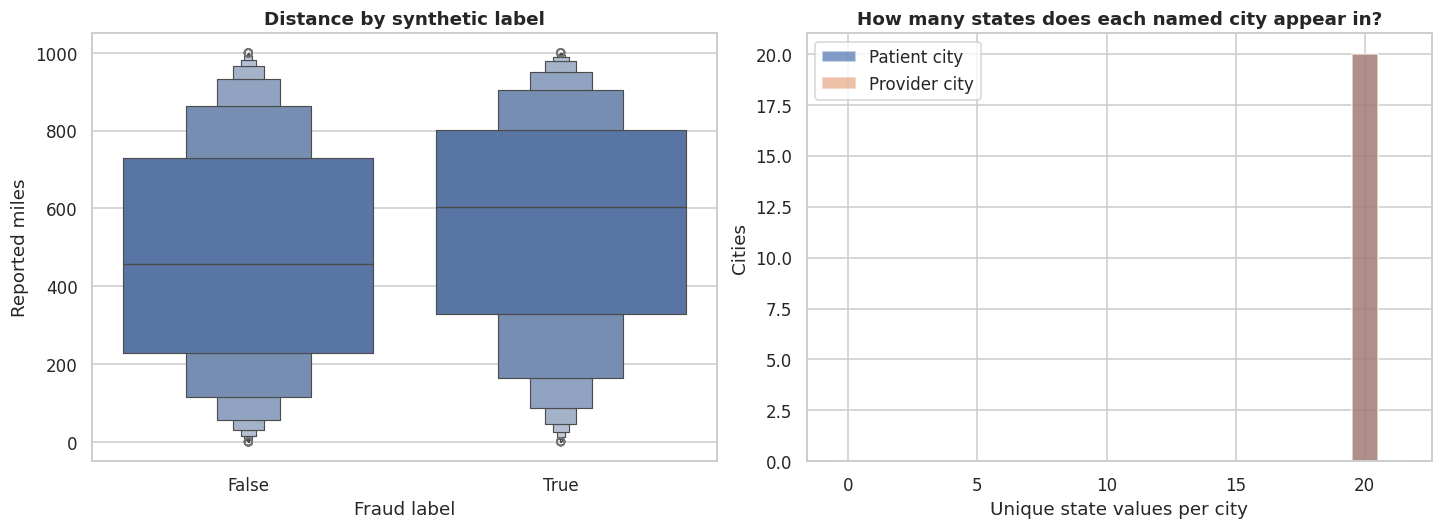

In [29]:
city_state=pd.DataFrame({
 'patient_states_per_city':df.groupby('Patient_City').Patient_State.nunique(),
 'provider_states_per_city':df.groupby('Provider_City').Provider_State.nunique()
})
print('Distinct state values per named city (first 10):');display(city_state.head(10))
print('Patient city-state pairs:',df[['Patient_City','Patient_State']].drop_duplicates().shape[0])
print('Provider city-state pairs:',df[['Provider_City','Provider_State']].drop_duplicates().shape[0])
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
sns.boxenplot(data=df,x='Is_Fraudulent',y='Provider_Patient_Distance_Miles',ax=axes[0])
axes[0].set(title='Distance by synthetic label',xlabel='Fraud label',ylabel='Reported miles')
axes[1].hist(city_state.patient_states_per_city,bins=np.arange(0,23)-.5,alpha=.7,label='Patient city')
axes[1].hist(city_state.provider_states_per_city,bins=np.arange(0,23)-.5,alpha=.5,label='Provider city')
axes[1].set(title='How many states does each named city appear in?',xlabel='Unique state values per city',ylabel='Cities')
axes[1].legend();saveplot('16_geography_and_distance_quality.png')

## 13. Clinical-code coverage and diagnosis × procedure co-occurrence

**Important distinction:** A high- or low-frequency diagnosis–procedure pair is not inherently clinically compatible or incompatible. Proper ICD-10/CPT/HCPCS/NAPPI/tariff-code validation needs a **versioned, payer-appropriate reference** and clinical context, including modifiers and episode/service dates.

For EDA we can inspect: coverage, count sufficiency, pair frequencies, pair-level label rates and conditional coding frequencies. A rare pair in a small sample may be ordinary. Using target-driven rates of all code pairs as features on the same rows would cause target encoding leakage; any later encoding must be **out-of-fold and time-aware**.

Distinct diagnosis codes: 20 | distinct procedure codes: 20
Observed diagnosis-procedure pairs: 400 of 400 possible pairs
Diagnosis × procedure dependence: chi2=1,267.7, p=4.414e-101, Cramers V=0.0579


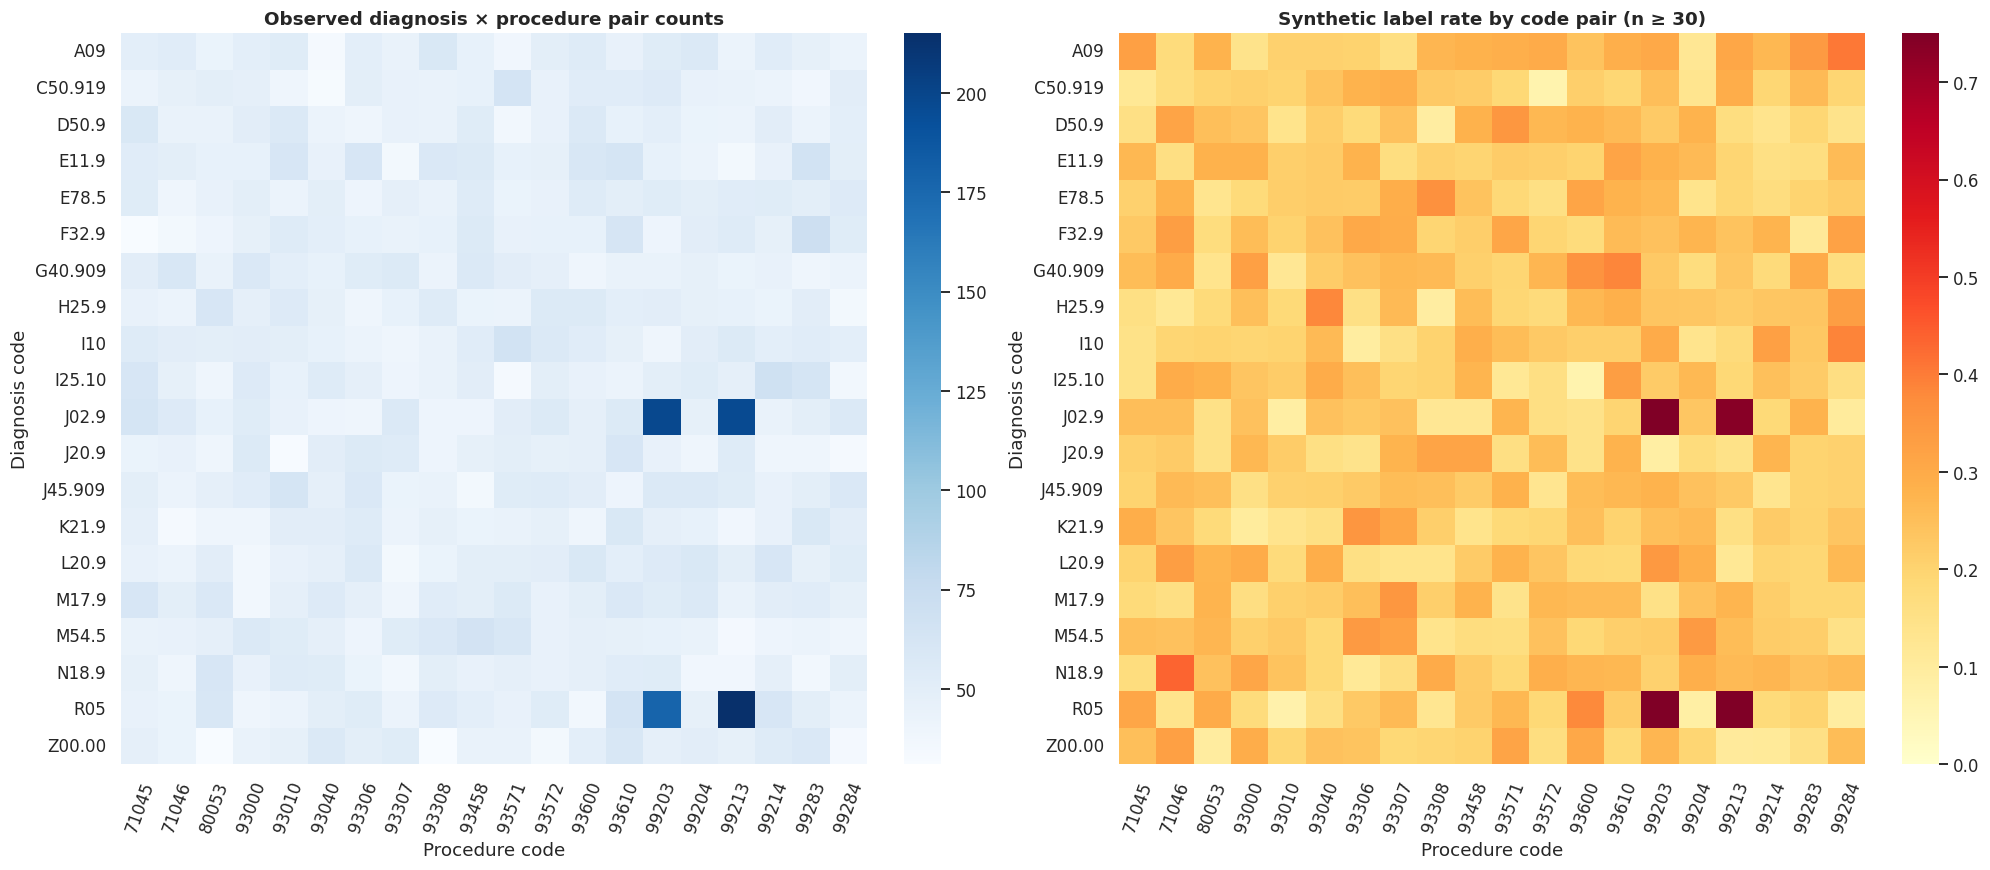

In [30]:
print('Distinct diagnosis codes:',df.Diagnosis_Code.nunique(),
      '| distinct procedure codes:',df.Procedure_Code.nunique())
pair_counts=pd.crosstab(df.Diagnosis_Code,df.Procedure_Code)
pair_label_rate=df.pivot_table(index='Diagnosis_Code',columns='Procedure_Code',values='Fraud',aggfunc='mean')
print('Observed diagnosis-procedure pairs:',int(pair_counts.gt(0).sum().sum()),
      'of',pair_counts.size,'possible pairs')
chi_pair=stats.chi2_contingency(pair_counts,correction=False)
print(f'Diagnosis × procedure dependence: chi2={chi_pair.statistic:,.1f}, p={chi_pair.pvalue:.4g},'
      f' Cramers V={cramers_v(pair_counts):.4f}')
fig,axes=plt.subplots(1,2,figsize=(18,7.8))
sns.heatmap(pair_counts,cmap='Blues',ax=axes[0]);axes[0].set(title='Observed diagnosis × procedure pair counts',xlabel='Procedure code',ylabel='Diagnosis code')
sns.heatmap(pair_label_rate,mask=pair_counts.lt(30),cmap='YlOrRd',vmin=0,vmax=.75,ax=axes[1])
axes[1].set(title='Synthetic label rate by code pair (n ≥ 30)',xlabel='Procedure code',ylabel='Diagnosis code')
for ax in axes: ax.tick_params(axis='x',rotation=70)
saveplot('17_diagnosis_procedure_cooccurrence.png')
pair_counts.to_csv(TABLE/'diagnosis_procedure_pair_counts.csv')
pair_label_rate.to_csv(TABLE/'diagnosis_procedure_label_rates_exploratory.csv')

## 14. Utilization intensity and claim normalization

**Candidate engineering hypotheses:** submitted amount per procedure and procedures per stay day may reveal unusual intensity. These are proxies and can be misleading across distinct service lines. A zero-day stay is not an appropriate denominator; define stay-normalized intensity **only** where it makes conceptual sense. Financial outliers require matched comparisons by procedure, complexity and tariff—not a global threshold.

,count,mean,std,min,5%,50%,90%,95%,99%,max
Amount_Per_Procedure,19900.0,372328.284748,447169.569388,827.717778,28131.129800,220312.932500,879439.374500,1.323663e+06,2.256664e+06,2.499394e+06
Procedures_Per_Stay_Day,3259.0,0.444992,0.980236,0.016667,0.031250,0.176471,0.900000,1.666667e+00,5.000000e+00,1.000000e+01
Patient_Cost_Share_Ratio,19900.0,0.006996,0.028051,0.000024,0.000503,0.002408,0.010459,2.007393e-02,8.953678e-02,8.542293e-01


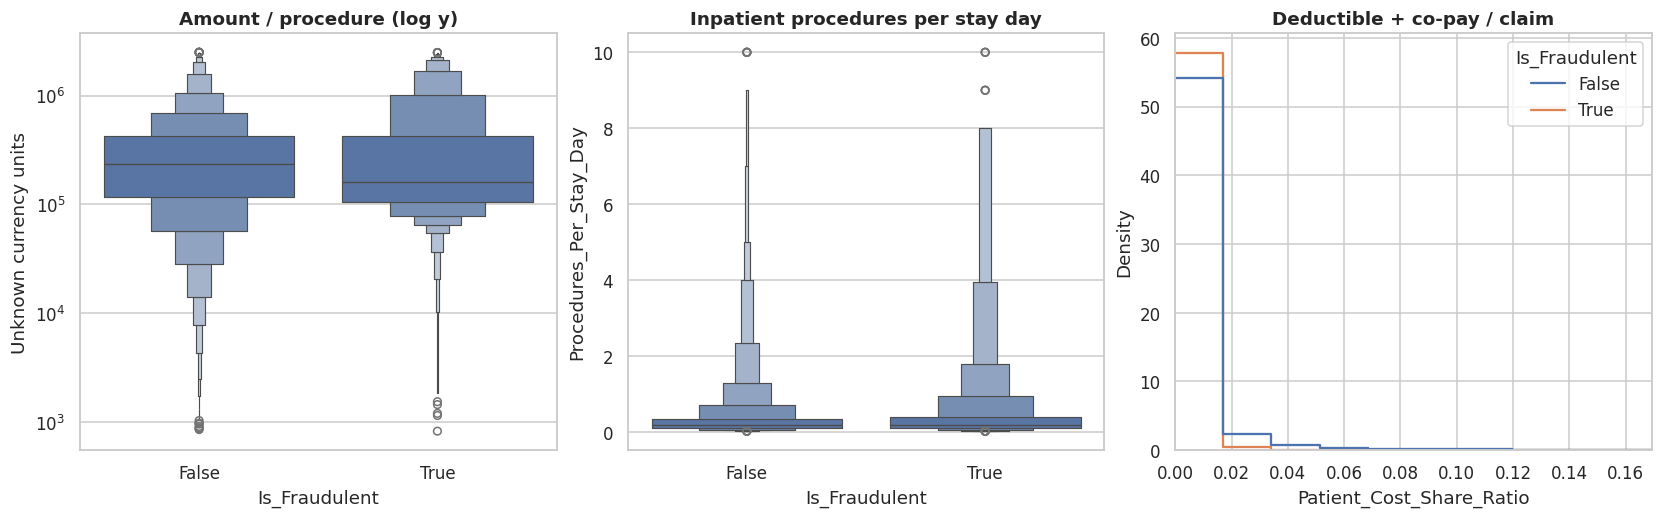

In [31]:
df['Amount_Per_Procedure']=df.Claim_Amount/df.Number_of_Procedures
df['Procedures_Per_Stay_Day']=np.where((df.Service_Type=='Inpatient') & (df.Length_of_Stay_Days>0),
                                    df.Number_of_Procedures/df.Length_of_Stay_Days, np.nan)
df['Patient_Cost_Share_Ratio']=(df.Deductible_Amount+df.CoPay_Amount)/df.Claim_Amount
intensity=df[['Amount_Per_Procedure','Procedures_Per_Stay_Day','Patient_Cost_Share_Ratio']].describe(percentiles=[.05,.5,.9,.95,.99]).T
display(intensity)
fig,axes=plt.subplots(1,3,figsize=(15,4.6))
sns.boxenplot(data=df,x='Is_Fraudulent',y='Amount_Per_Procedure',ax=axes[0])
axes[0].set_yscale('log');axes[0].set(title='Amount / procedure (log y)',ylabel='Unknown currency units')
sns.boxenplot(data=df.dropna(subset=['Procedures_Per_Stay_Day']),x='Is_Fraudulent',y='Procedures_Per_Stay_Day',ax=axes[1])
axes[1].set(title='Inpatient procedures per stay day')
sns.histplot(data=df,x='Patient_Cost_Share_Ratio',hue='Is_Fraudulent',common_norm=False,
             stat='density',element='step',fill=False,bins=50,ax=axes[2])
axes[2].set(xlim=(0,min(1,df.Patient_Cost_Share_Ratio.quantile(.995))),title='Deductible + co-pay / claim')
saveplot('18_utilization_and_cost_intensity.png')

## 15. Provider-level descriptive profiling: exposure, peer comparisons and uncertainty

A provider profile uses **Hospital_ID as an exploratory grouping only**. Before assigning provider risk, check whether an ID refers to a stable entity. We can aggregate claim count, median amount, procedure intensity and retrospective label rate. These are descriptive, **not deployable prospective fraud scores**: the label rate itself is outcome information and must never appear in a claim-level predictive feature computed from its own or future labels.

Use minimum sample-size constraints, Wilson confidence intervals and cautious shrinkage. Providers with 4 claims and 2 synthetic positives should not outrank providers with hundreds of claims on the basis of the raw rate alone. For a demonstration we show posterior-shrunk label rates using a weak empirical Beta prior with effective sample size 20; this is **illustrative ranking**, not validated Bayes fraud inference.

In [32]:
provider=df.groupby('Hospital_ID').agg(
 claims=('Claim_ID','size'), labelled=('Fraud','sum'),label_rate=('Fraud','mean'),
 total_claimed=('Claim_Amount','sum'),median_claim=('Claim_Amount','median'),
 mean_procedures=('Number_of_Procedures','mean'),
 mean_distance=('Provider_Patient_Distance_Miles','mean'),
 categories=('Provider_Type','nunique'), specialties=('Provider_Specialty','nunique'),
 cities=('Provider_City','nunique'),states=('Provider_State','nunique')
).reset_index()
provider['label_ci_low'],provider['label_ci_high']=wilson_table(provider.labelled,provider.claims)
prior_strength=20
provider['label_rate_shrunk']=(provider.labelled+prior_strength*df.Fraud.mean())/(provider.claims+prior_strength)
provider.to_csv(TABLE/'provider_exploratory_profiles.csv',index=False)
display(provider.describe(percentiles=[.05,.5,.95,.99]).T.round(3))
print('All provider IDs with >1 distinct provider type:',int((provider.categories>1).sum()),'/',len(provider))
print('All provider IDs with >1 distinct state:',int((provider.states>1).sum()),'/',len(provider))
print('Provider sample-size percentiles:',provider.claims.quantile([0,.1,.5,.9,.99,1]).to_dict())

,count,mean,std,min,5%,50%,95%,99%,max
Hospital_ID,1000.0,5.005000e+02,288.819,1.000,5.095000e+01,5.005000e+02,9.500500e+02,9.900100e+02,1.000000e+03
claims,1000.0,1.990000e+01,4.562,7.000,1.300000e+01,2.000000e+01,2.800000e+01,3.101000e+01,3.500000e+01
labelled,1000.0,4.883000e+00,2.178,0.000,2.000000e+00,5.000000e+00,9.000000e+00,1.100000e+01,1.400000e+01
label_rate,1000.0,2.460000e-01,0.099,0.000,9.100000e-02,2.400000e-01,4.170000e-01,5.000000e-01,6.360000e-01
total_claimed,1000.0,2.478832e+07,6410808.178,6305999.880,1.488344e+07,2.448075e+07,3.624748e+07,4.268103e+07,4.471476e+07
median_claim,1000.0,1.229428e+06,249277.762,601832.040,8.251864e+05,1.223363e+06,1.660782e+06,1.832140e+06,2.039843e+06
mean_procedures,1000.0,5.513000e+00,0.670,3.300,4.458000e+00,5.469000e+00,6.632000e+00,7.125000e+00,7.562000e+00
mean_distance,1000.0,4.981810e+02,67.977,266.756,3.865360e+02,4.988700e+02,6.114780e+02,6.554130e+02,7.455530e+02
categories,1000.0,5.726000e+00,0.509,3.000,5.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00,6.000000e+00
specialties,1000.0,8.534000e+00,1.121,4.000,7.000000e+00,9.000000e+00,1.000000e+01,1.000000e+01,1.000000e+01


All provider IDs with >1 distinct provider type: 1000 / 1000
All provider IDs with >1 distinct state: 1000 / 1000
Provider sample-size percentiles: {0.0: 7.0, 0.1: 14.0, 0.5: 20.0, 0.9: 26.0, 0.99: 31.00999999999999, 1.0: 35.0}


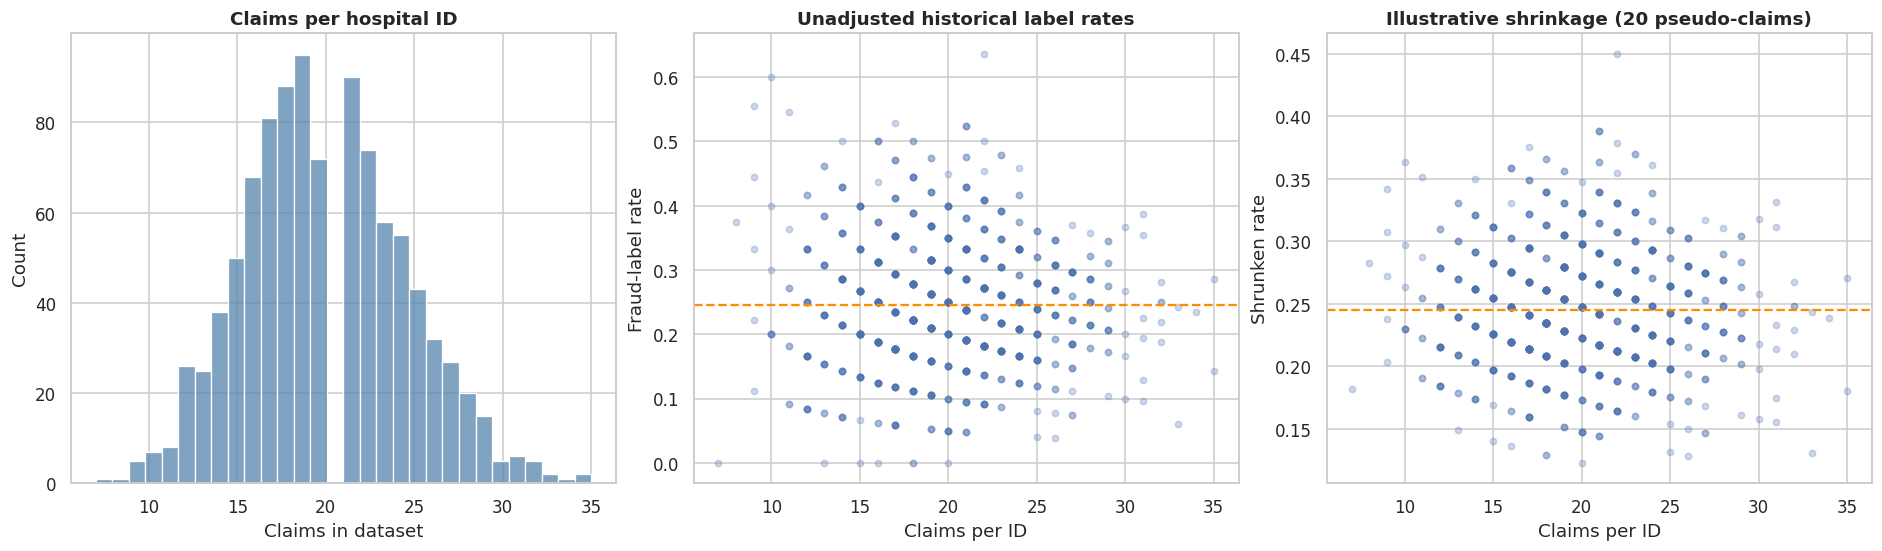

In [33]:
fig,axes=plt.subplots(1,3,figsize=(17,4.9))
sns.histplot(provider.claims,bins=30,ax=axes[0],color="#5485AC");axes[0].set(title='Claims per hospital ID',xlabel='Claims in dataset')
axes[1].scatter(provider.claims,provider.label_rate,alpha=.27,s=17)
axes[1].axhline(df.Fraud.mean(),color='darkorange',linestyle='--');axes[1].set(title='Unadjusted historical label rates',xlabel='Claims per ID',ylabel='Fraud-label rate')
axes[2].scatter(provider.claims,provider.label_rate_shrunk,alpha=.27,s=17)
axes[2].axhline(df.Fraud.mean(),color='darkorange',linestyle='--');axes[2].set(title='Illustrative shrinkage (20 pseudo-claims)',xlabel='Claims per ID',ylabel='Shrunken rate')
saveplot('19_provider_volume_and_shrinkage.png')

## 16. Patient relationships: can this file support longitudinal networks?

Network-based FWA patterns include repeated patient–provider interactions, shared patients across connected practices, and referral clusters. Such questions require repeated observations of a **stable** patient and provider ID. We quantify unique patients and repeated identities **after cleaning**, distinguishing duplicate-claim repeats from genuine separate-claim repeats. A dense bipartite graph cannot be inferred from one-time patients.

In [34]:
patient_counts=df.groupby('Patient_ID').Claim_ID.nunique()
repeated=patient_counts[patient_counts>1]
print(f'Unique patients in clean cohort: {patient_counts.size:,}')
print(f'Patients with multiple distinct claims: {len(repeated):,}')
print('Claim counts per patient:');display(patient_counts.value_counts().sort_index().rename_axis('distinct_claims').to_frame('patients'))
print('Patients visiting multiple hospital IDs:',int(df.groupby('Patient_ID').Hospital_ID.nunique().gt(1).sum()))
print('Policies shared by multiple distinct patients:',int(df.groupby('Policy_Number').Patient_ID.nunique().gt(1).sum()))

Unique patients in clean cohort: 19,894
Patients with multiple distinct claims: 6
Claim counts per patient:


,patients
distinct_claims,
1,19888
2,6


Patients visiting multiple hospital IDs: 6
Policies shared by multiple distinct patients: 0


## 17. Validate historical claim counters and provider identity stability

`Number_of_Previous_Claims_Provider` sounds retrospective, but a real previous-claim count depends on **which claims were known at the scoring time**. We reconstruct the number of earlier records per hospital ID using `Claim_Date` and compare with the supplied field. Same-day events are not ordered, so we use the earliest possible count at the day boundary, excluding all same-day claims to avoid artificial ordering.

A mismatch can be due to pre-dataset history, an incomplete extract, multiple submission timestamps or synthetic generation. It means we **cannot** automatically treat the supplied count as verified event history. Likewise, changing specialty/state within a Hospital_ID is a serious entity-integrity concern rather than evidence of mobile providers.

Reported historical provider count versus reconstructable earlier records:
                                    Number_of_Previous_Claims_Provider  \
Number_of_Previous_Claims_Provider                            1.000000   
Earlier_Claims_In_Extract                                     0.091098   

                                    Earlier_Claims_In_Extract  
Number_of_Previous_Claims_Provider                   0.091098  
Earlier_Claims_In_Extract                            1.000000  
Exact agreement: 0.04778894472361809


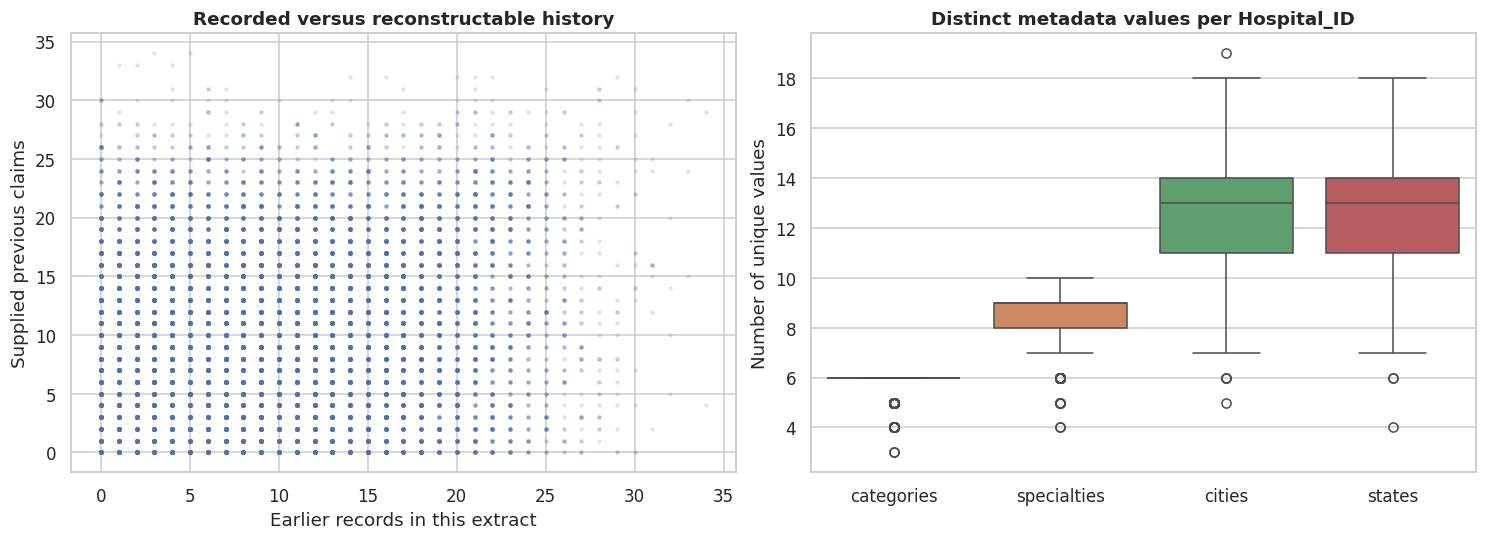

In [35]:
# Number of claims with a STRICTLY earlier claim date in this file (no same-day ordering assumed).
ordered=df.sort_values(['Hospital_ID','Claim_Date','Claim_ID']).copy()
daily=ordered.groupby(['Hospital_ID','Claim_Date'],sort=True).size().rename('same_day_count').reset_index()
daily['Earlier_Claims_In_Extract']=daily.groupby('Hospital_ID').same_day_count.cumsum()-daily.same_day_count
ordered=ordered.merge(daily[['Hospital_ID','Claim_Date','Earlier_Claims_In_Extract']],
                      on=['Hospital_ID','Claim_Date'],validate='many_to_one')
print('Reported historical provider count versus reconstructable earlier records:')
print(ordered[['Number_of_Previous_Claims_Provider','Earlier_Claims_In_Extract']].corr(method='spearman'))
print('Exact agreement:',(ordered.Number_of_Previous_Claims_Provider==ordered.Earlier_Claims_In_Extract).mean())
fig,axes=plt.subplots(1,2,figsize=(13.4,4.8))
axes[0].scatter(ordered.Earlier_Claims_In_Extract,ordered.Number_of_Previous_Claims_Provider,s=4,alpha=.13)
axes[0].set(title='Recorded versus reconstructable history',xlabel='Earlier records in this extract',ylabel='Supplied previous claims')
prov_multi=provider[['categories','specialties','cities','states']]
sns.boxplot(data=prov_multi,ax=axes[1]);axes[1].set(title='Distinct metadata values per Hospital_ID',ylabel='Number of unique values')
saveplot('20_prior_count_and_entity_consistency.png')

## 18. Correlation map and multicollinearity

For continuous variables, **Spearman correlation** assesses monotonic association without requiring normality. A correlation matrix is useful for reducing redundant features and identifying derived-variable relationships; it does not show causal connections or interactions. Exclude IDs and the target from the numeric heatmap, then examine target effects separately via the earlier statistical tests.

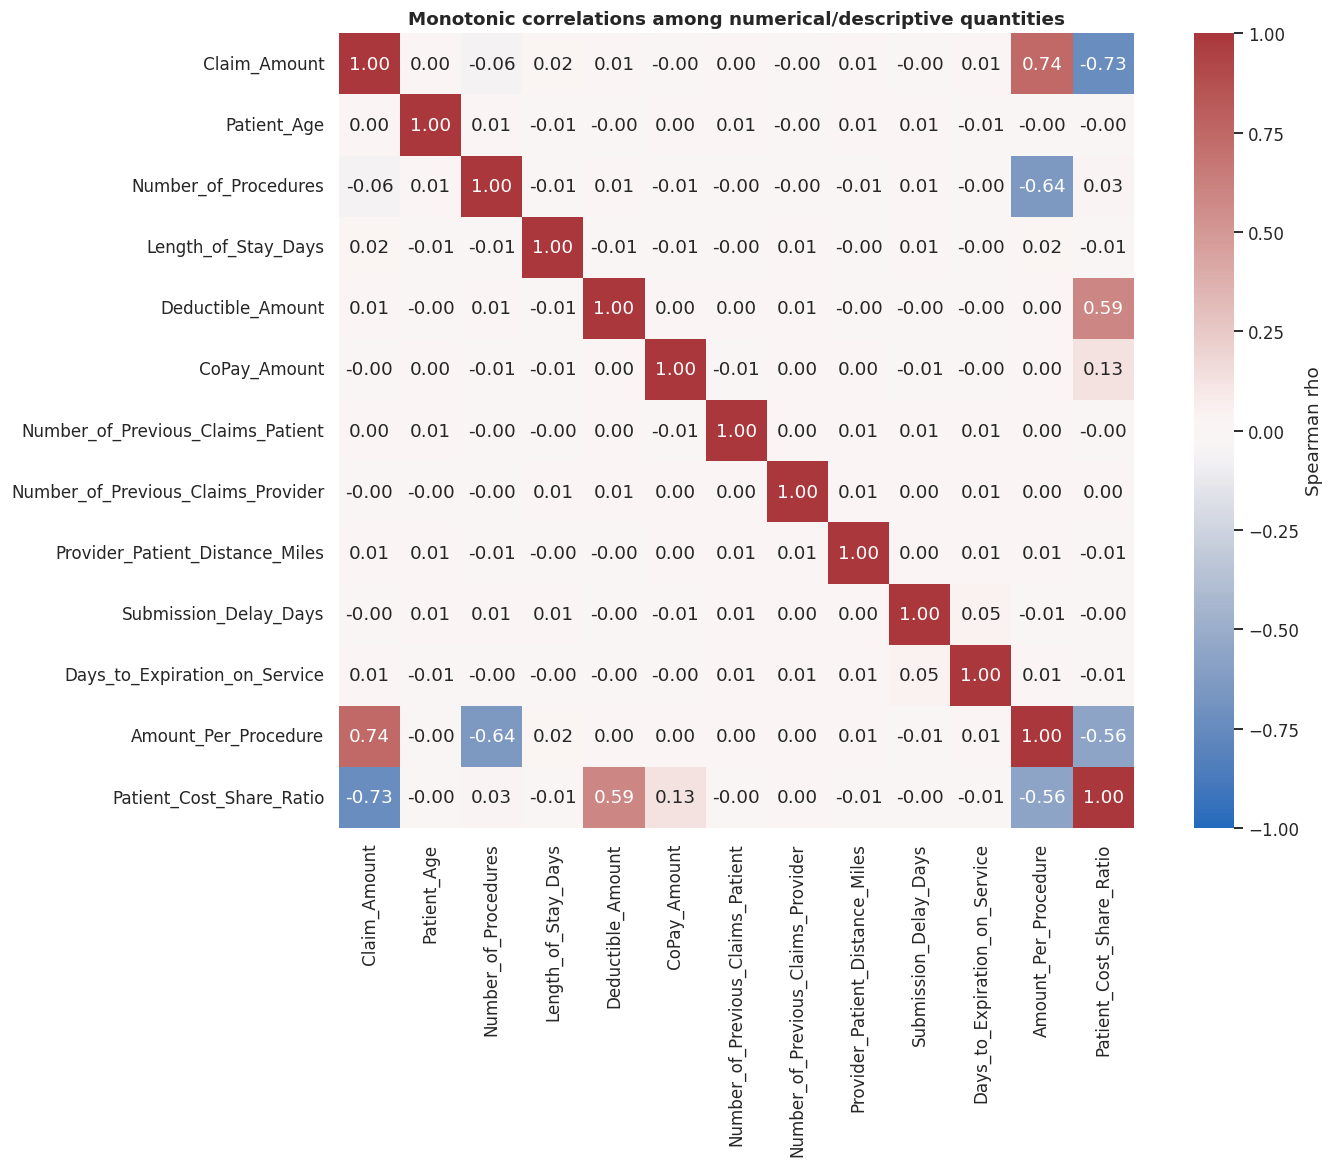

In [36]:
corr_fields=measures+['Submission_Delay_Days','Days_to_Expiration_on_Service',
                      'Amount_Per_Procedure','Patient_Cost_Share_Ratio']
rho=df[corr_fields].corr(method='spearman')
fig,ax=plt.subplots(figsize=(12.8,10.5))
sns.heatmap(rho,annot=True,fmt='.2f',cmap='vlag',vmin=-1,vmax=1,center=0,
            square=True,ax=ax,cbar_kws={'label':'Spearman rho'})
ax.set_title('Monotonic correlations among numerical/descriptive quantities')
saveplot('21_spearman_correlation_map.png')
rho.to_csv(TABLE/'spearman_correlation_matrix.csv')

## 19. Explicit leakage / bias / transportability review

A feature is valid only if it can be known at the intended **prediction timestamp**, matches the operational meaning of the data, and does not encode the target itself. We create an audit table with proposed guardrails. Some variables are useful for descriptive EDA but unsuitable for a future claims-scoring model as-is.

In [37]:
leakage_table=pd.DataFrame([
 ('Claim_ID, Patient_ID, Policy_Number','Exclude raw keys from prediction','High-cardinality identifiers and collision risk; use only for joins/history'),
 ('Hospital_ID','Cautious; group/holdout stability audit','Entity metadata inconsistent; avoid memorize-the-ID scoring'),
 ('Procedure_Code','Categorical, never numeric magnitude','Validate code system and effective dates; no numeric ordering'),
 ('Provider_Type, Provider_Specialty','Exploratory, require external metadata validation','Rates partly reflect synthetic label generation; group fairness concerns'),
 ('Patient_City/State, Provider_City/State','Do not infer real geography','City/state combinations are synthetic and inconsistent'),
 ('Provider_Patient_Distance_Miles','Data provenance validation before deployment','Cannot corroborate reported distance with locations'),
 ('Claim_Submitted_Late','Potentially redundant with lag','Deterministic proxy for submission delay in the file'),
 ('Number_of_Previous_Claims_*','Recompute strictly as-of score time','Reported history needs reconciliation; future records create leakage'),
 ('Discharge_Type, Length_of_Stay_Days','Availability depends on scoring point','May not be known before discharge; model must define adjudication timing'),
 ('Policy_Expiration_Date','Validity check as-of service','Eligibility requires complete membership and coverage history'),
 ('Is_Fraudulent','Never a feature','Synthetic outcome; do not use contemporaneous provider label rates as inputs'),
 ('Diagnosis × Procedure target rates','Only out-of-fold / time-aware, if used','Full-dataset target encoding leaks label information'),
],columns=['attribute','proposed_action','reason'])
display(leakage_table)
leakage_table.to_csv(TABLE/'feature_leakage_and_bias_audit.csv',index=False)

,attribute,proposed_action,reason
0,"Claim_ID, Patient_ID, Policy_Number",Exclude raw keys from prediction,High-cardinality identifiers and collision ris...
1,Hospital_ID,Cautious; group/holdout stability audit,Entity metadata inconsistent; avoid memorize-t...
2,Procedure_Code,"Categorical, never numeric magnitude",Validate code system and effective dates; no n...
3,"Provider_Type, Provider_Specialty","Exploratory, require external metadata validation",Rates partly reflect synthetic label generatio...
4,"Patient_City/State, Provider_City/State",Do not infer real geography,City/state combinations are synthetic and inco...
5,Provider_Patient_Distance_Miles,Data provenance validation before deployment,Cannot corroborate reported distance with loca...
6,Claim_Submitted_Late,Potentially redundant with lag,Deterministic proxy for submission delay in th...
7,Number_of_Previous_Claims_*,Recompute strictly as-of score time,Reported history needs reconciliation; future ...
8,"Discharge_Type, Length_of_Stay_Days",Availability depends on scoring point,May not be known before discharge; model must ...
9,Policy_Expiration_Date,Validity check as-of service,Eligibility requires complete membership and c...


## 20. Hypothesis register: EDA → possible engineering → evaluation plan

The purpose of EDA is to create *testable, temporally valid hypotheses*, not to manufacture a fraud-risk score. Each proposed feature below includes a question it answers, evidence needed and a falsification or evaluation condition.

In [38]:
roadmap=pd.DataFrame([
 ('Submission delay','Claim_Date − Service_Date, in days','Dates available at claim submission','Verify filing timelines by payer and service; compare with pre-existing late flag','Avoid keeping exact duplicate indicators without added benefit'),
 ('Amount intensity','Claim_Amount / Number_of_Procedures','Both billed at submission','Validate currency, tariff schedules and procedure units','Evaluate by code, service line and provider peers'),
 ('Stay-adjusted utilization','Procedures / stay days, only for suitable inpatient episodes','Admission/discharge verified at scoring point','Risk/acuity and episode-level denominators needed','Exclude non-inpatient or zero-stay rows'),
 ('Provider volume anomaly','Trailing 30/90-day claim count vs historical peer baseline','Events known before scoring time','Stable provider IDs and exposure normalization','Never compute with future claims'),
 ('Provider financial anomaly','Peer-adjusted median / p95 amount','Claim prices and correct currency','Specialty, location, case mix, contract/tariff','Do not use a universal amount threshold'),
 ('Rare diagnosis-procedure combination','Log frequency with time-aware smoothing','Code tables as of claim time','Versioned compatibility/coverage policy rules','Frequency ≠ clinical contraindication'),
 ('Provider/case-mix concentration','Specialty/procedure entropy and peer deviation','Verified stable provider registry','Minimum denominator and adequate lookback','Hospital_ID metadata inconsistent here'),
 ('Patient/provider repetition','Repeated contacts, short-interval cycles','Stable patient and provider keys','Longitudinal claims, visits, referrals, coverage','Nearly no repeated genuine patients here'),
 ('Travel exception','Geo-distance confirmed from validated location','Reliable locations or GPS/addresses','Check city–state mapping and true travel time','Dataset geography fails quality checks'),
 ('Eligibility exception','Service outside active coverage period','Full effective-dated policy history','Coverage rules, grace periods and claims reversals','No expired-at-service examples in this dataset'),
 ('Fairness and monitoring','Group-wise calibration / false-positive rates','Access to verified audit outcomes','Subgroup validity, disparate impact, appeals','Do not use demographic correlation as clinical justification'),
],columns=['hypothesis','candidate_feature','required_information','validation_needed','caveat'])
display(roadmap)
roadmap.to_csv(TABLE/'feature_engineering_hypotheses.csv',index=False)

,hypothesis,candidate_feature,required_information,validation_needed,caveat
0,Submission delay,"Claim_Date − Service_Date, in days",Dates available at claim submission,Verify filing timelines by payer and service; ...,Avoid keeping exact duplicate indicators witho...
1,Amount intensity,Claim_Amount / Number_of_Procedures,Both billed at submission,"Validate currency, tariff schedules and proced...","Evaluate by code, service line and provider peers"
2,Stay-adjusted utilization,"Procedures / stay days, only for suitable inpa...",Admission/discharge verified at scoring point,Risk/acuity and episode-level denominators needed,Exclude non-inpatient or zero-stay rows
3,Provider volume anomaly,Trailing 30/90-day claim count vs historical p...,Events known before scoring time,Stable provider IDs and exposure normalization,Never compute with future claims
4,Provider financial anomaly,Peer-adjusted median / p95 amount,Claim prices and correct currency,"Specialty, location, case mix, contract/tariff",Do not use a universal amount threshold
5,Rare diagnosis-procedure combination,Log frequency with time-aware smoothing,Code tables as of claim time,Versioned compatibility/coverage policy rules,Frequency ≠ clinical contraindication
6,Provider/case-mix concentration,Specialty/procedure entropy and peer deviation,Verified stable provider registry,Minimum denominator and adequate lookback,Hospital_ID metadata inconsistent here
7,Patient/provider repetition,"Repeated contacts, short-interval cycles",Stable patient and provider keys,"Longitudinal claims, visits, referrals, coverage",Nearly no repeated genuine patients here
8,Travel exception,Geo-distance confirmed from validated location,Reliable locations or GPS/addresses,Check city–state mapping and true travel time,Dataset geography fails quality checks
9,Eligibility exception,Service outside active coverage period,Full effective-dated policy history,"Coverage rules, grace periods and claims rever...",No expired-at-service examples in this dataset


## 21. Final EDA synthesis and benchmarking protocol

### What we have established

- **Data integrity is a prerequisite:** 100 repeated claim IDs require explicit handling; label conflicts cannot be repaired by guessing.
- **The synthetic labels are common:** roughly one quarter of records carry a positive label. A realistic operational class balance must be evaluated independently.
- **Conditional label rates vary substantially by provider type, specialty and certain codes.** These associations could reveal how the synthetic labels were constructed, so they must not be confused with real provider behavior.
- **Provider identity is not stable:** every hospital ID spans multiple provider categories and geographic states. Group-level profiling remains descriptive.
- **Patient history is sparse:** virtually all cleaned patients have only one claim. Patient–provider-network conclusions cannot be tested well here.
- **Clinical compatibility cannot be inferred solely from co-occurrence:** only independently validated code rules could support such a claim.

### Next experiment: defensible modelling (not executed in this notebook)

1. Resolve claim IDs using adjudicated labels; preserve a raw immutable snapshot and decision log.
2. Hold out a **later** claim-date period (and consider a provider-group holdout) before choosing features or interpreting supervised associations as feature-selection results.
3. Fit all preprocessors, imputers, rare-category thresholds, scalers and target encoders **on training data only**; calculate historical counters strictly as of each claim.
4. Start with Logistic Regression and XGBoost baselines, plus Isolation Forest as a distinct unsupervised anomaly-ranking objective.
5. Report PR-AUC, ROC-AUC, calibration, precision/recall at investigator review capacity, expected financial yield and uncertainty intervals. Select thresholds **only on validation data**.
6. Examine fair-treatment and provider-group stability, monitoring for drift and errors; incorporate human clinical review before adverse decisions.
7. Repeat on realistic prevalence, trusted provider registries, vetted clinical edits and true adjudicated investigation outcomes.

**Notebook limitations:** Statistical tests are exploratory, not pre-registered. Repeated rows and unobserved provider/patient dependence violate some simple independence assumptions. Nominal confidence intervals quantify sample variation only, not uncertainty from synthetic generation. Currency, diagnosis/procedure versions, geographical provenance and policy contracts are unspecified. No real fraud allegations follow from this analysis.

In [39]:
# Compact summary exported for convenient reuse in a README/report.
eda_summary=pd.DataFrame([
 ('Rows in source archive',len(raw)),
 ('Rows in primary analysis cohort',len(df)),
 ('Features in original file',raw.shape[1]),
 ('Positive synthetic labels in cohort',int(df.Fraud.sum())),
 ('Positive synthetic label rate',f'{df.Fraud.mean():.4%}'),
 ('Distinct hospital IDs',df.Hospital_ID.nunique()),
 ('Repeated Claim_IDs in raw source',len(repeated_ids)),
 ('Repeated IDs with conflicting labels',len(conflicting_ids)),
 ('Exact duplicate rows in raw source',int(raw.duplicated().sum())),
 ('Unique patients in clean cohort',df.Patient_ID.nunique()),
 ('Patients with more than one distinct claim',int((patient_counts>1).sum())),
 ('Hospital IDs spanning >1 provider type',int((provider.categories>1).sum())),
 ('Distinct diagnosis × procedure combinations',int(pair_counts.gt(0).sum().sum())),
 ('Recorded late flag matches delay >30 days',f'{(df.Submission_Delay_Days.gt(30)==df.Claim_Submitted_Late).mean():.2%}')
],columns=['metric','value'])
display(eda_summary)
eda_summary.to_csv(TABLE/'eda_summary_kpis.csv',index=False)
print(f'EDA complete: {len(list(FIG.glob("*.png")))} visualizations, {len(list(TABLE.glob("*.csv")))} tables exported.')

,metric,value
0,Rows in source archive,20100
1,Rows in primary analysis cohort,19900
2,Features in original file,30
3,Positive synthetic labels in cohort,4883
4,Positive synthetic label rate,24.5377%
5,Distinct hospital IDs,1000
6,Repeated Claim_IDs in raw source,100
7,Repeated IDs with conflicting labels,72
8,Exact duplicate rows in raw source,28
9,Unique patients in clean cohort,19894


EDA complete: 22 visualizations, 19 tables exported.
